#**Applied AI - Final Project**

## Title: Intelligent Business Document Processing Using NLP

### Project Objective -
Design and evaluate an AI-assisted system that classifies business documents and retrieves relevant information using Natural Language Processing.

### Techniques -
- TF-IDF and text classification
- Logistic Regression and Linear SVM
- BM25 and semantic retrieval
- Model evaluation and statistical comparison
- A/B testing methodology

### Project Scope -
This notebook implements and evaluates document classification and retrieval components. Other system components, including access control and human review, are addressed in the proposed architecture.


##Step 2 - Install the required libraries
- These packages will support realistic sample-data generation, keyword retrieval, and semantic embeddings

In [ ]:
!pip -q install faker rank-bm25 sentence-transformers

##Step 3 - Generate our business document dataset

In [ ]:
import pandas as pd
import numpy as np
import random
from faker import Faker

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
fake = Faker()
Faker.seed(SEED)

# Four document categories
categories = [
    "Invoice",
    "Purchase Order",
    "Shipping Notice",
    "Service Report"
]

# Different writing styles for each category
templates = {
    "Invoice": [
        "Invoice {doc_id} issued to {company} on {date}. "
        "Payment of ${amount} is due within {days} days.",

        "Billing statement {doc_id} for {company}. "
        "Total outstanding balance: ${amount}. "
        "Payment deadline is {date}.",

        "Account {company} received invoice reference {doc_id}. "
        "Amount payable is ${amount} for services provided."
    ],

    "Purchase Order": [
        "Purchase order {doc_id} submitted by {company} on {date}. "
        "Requested quantity is {quantity} units.",

        "Procurement request {doc_id}: {company} ordered "
        "{quantity} units with an estimated value of ${amount}.",

        "Order authorization {doc_id} confirms the purchase of "
        "{quantity} items for {company}."
    ],

    "Shipping Notice": [
        "Shipment {doc_id} for {company} was dispatched on {date}. "
        "Estimated delivery is within {days} days.",

        "Delivery notification {doc_id}: {quantity} units "
        "are in transit to {company}.",

        "Logistics update {doc_id}: delivery for {company} "
        "was postponed because inventory was unavailable."
    ],

    "Service Report": [
        "Service report {doc_id} for {company} dated {date}. "
        "Technician completed routine equipment inspection.",

        "Maintenance record {doc_id}: equipment at {company} "
        "required repair and performance testing.",

        "Technical service summary {doc_id} confirms "
        "inspection and replacement of faulty components."
    ]
}

records = []

for category in categories:
    for i in range(50):
        data = {
            "doc_id": fake.bothify(text="DOC-#####"),
            "company": fake.company(),
            "date": str(fake.date_this_year()),
            "amount": round(random.uniform(100, 10000), 2),
            "days": random.randint(5, 45),
            "quantity": random.randint(1, 500)
        }

        # Reserve one template per class for unseen-template testing
        template_id = i % 3
        text = templates[category][template_id].format(**data)

        records.append({
            "document_id": f"DOC-{len(records)+1:04d}",
            "category": category,
            "text": text,
            "template_id": template_id
        })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nDocuments per category:")
print(df["category"].value_counts())

display(df.head(8))

Dataset shape: (200, 4)

Documents per category:
category
Invoice            50
Purchase Order     50
Shipping Notice    50
Service Report     50
Name: count, dtype: int64


,document_id,category,text,template_id
0,DOC-0001,Invoice,Invoice DOC-10433 issued to Doyle Ltd on 2026-...,0
1,DOC-0002,Invoice,Billing statement DOC-81960 for Davis and Sons...,1
2,DOC-0003,Invoice,Account Cole LLC received invoice reference DO...,2
3,DOC-0004,Invoice,Invoice DOC-02654 issued to Lewis LLC on 2026-...,0
4,DOC-0005,Invoice,Billing statement DOC-61559 for Roman-Blair. T...,1
5,DOC-0006,Invoice,Account Ray-Bush received invoice reference DO...,2
6,DOC-0007,Invoice,Invoice DOC-34131 issued to Ramirez-Reid on 20...,0
7,DOC-0008,Invoice,"Billing statement DOC-55341 for Reid, Ferguson...",1


##Check dataset quality

In [ ]:
# Check missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate documents:", df["text"].duplicated().sum())

# Examine document length
df["word_count"] = df["text"].str.split().str.len()

print("\nDocument length statistics:")
display(df.groupby("category")["word_count"].describe().round(2))

# Check template distribution
print("\nTemplate distribution:")
display(pd.crosstab(df["category"], df["template_id"]))

Missing values:
document_id    0
category       0
text           0
template_id    0
dtype: int64

Duplicate documents: 0

Document length statistics:


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Invoice,50.0,15.20,1.53,13.0,14.0,15.0,16.0,18.0
Purchase Order,50.0,13.78,1.47,11.0,13.0,14.0,14.0,16.0
Service Report,50.0,12.52,1.59,11.0,11.0,12.0,14.0,15.0
Shipping Notice,50.0,13.48,2.01,10.0,12.0,13.5,15.0,17.0



Template distribution:


template_id,0,1,2
category,,,
Invoice,17,17,16
Purchase Order,17,17,16
Service Report,17,17,16
Shipping Notice,17,17,16


## Step 4 - Exploratory Data Analysis (EDA)

This section examines category balance and document-length
distributions before NLP model development.

The analysis helps identify potential dataset biases,
including differences in document length across categories.


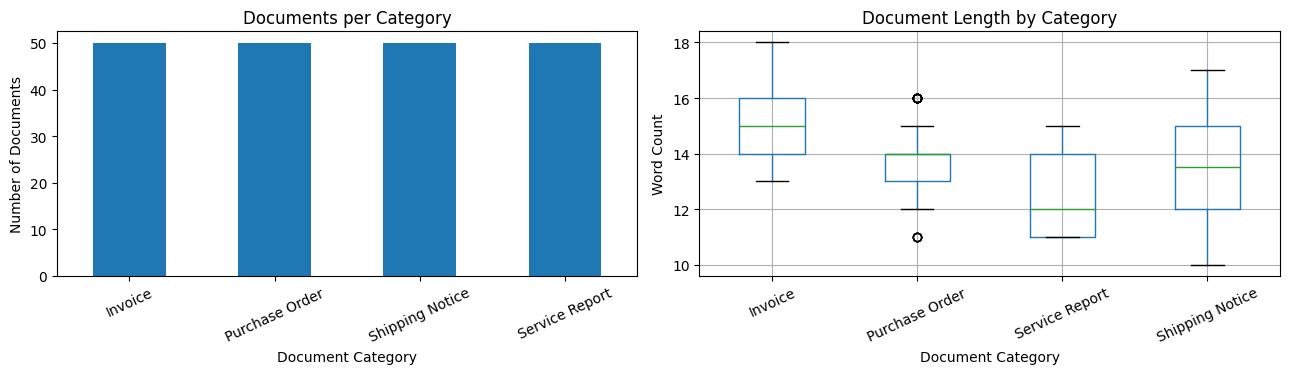

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Document distribution
df["category"].value_counts().plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Documents per Category")
axes[0].set_xlabel("Document Category")
axes[0].set_ylabel("Number of Documents")
axes[0].tick_params(axis="x", rotation=25)

# Document length distribution
df.boxplot(
    column="word_count",
    by="category",
    ax=axes[1]
)
axes[1].set_title("Document Length by Category")
axes[1].set_xlabel("Document Category")
axes[1].set_ylabel("Word Count")
axes[1].tick_params(axis="x", rotation=25)

plt.suptitle("")
plt.tight_layout()
plt.show()

## What results tell -
- Category distribution: All four categories contain 50 documents each, so our dataset is balanced.

- Document length: Invoices generally contain more words than service reports. This suggests that document length might influence classification.

- Dataset limitation: Our documents are short and generated using only three templates per category. We need to investigate whether our models learn meaningful language patterns or simply recognize template wording.

##Step 5 - NLP Model Development: TF-IDF + Logistic Regression

This experiment evaluates whether a machine learning model can
classify business documents based on their textual content.

To reduce template leakage, documents generated using templates
0 and 1 are used for training, while documents generated using
template 2 are reserved for testing.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Split dataset by template rather than randomly
train_df = df[df["template_id"].isin([0, 1])].copy()
test_df = df[df["template_id"] == 2].copy()

X_train = train_df["text"]
y_train = train_df["category"]

X_test = test_df["text"]
y_test = test_df["category"]

print("Training documents:", len(train_df))
print("Testing documents:", len(test_df))

print("\nTraining category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training documents: 136
Testing documents: 64

Training category distribution:
category
Invoice            34
Purchase Order     34
Shipping Notice    34
Service Report     34
Name: count, dtype: int64

Testing category distribution:
category
Invoice            16
Purchase Order     16
Shipping Notice    16
Service Report     16
Name: count, dtype: int64


Logistic Regression Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

        Invoice       1.00      1.00      1.00        16
 Purchase Order       1.00      1.00      1.00        16
 Service Report       1.00      1.00      1.00        16
Shipping Notice       1.00      1.00      1.00        16

       accuracy                           1.00        64
      macro avg       1.00      1.00      1.00        64
   weighted avg       1.00      1.00      1.00        64



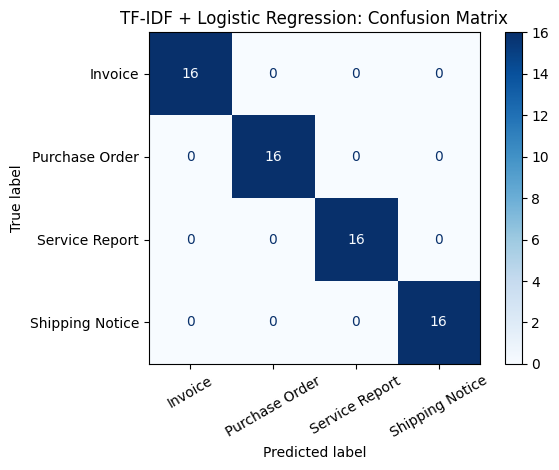

In [ ]:
# TF-IDF converts text into numerical features
# Logistic Regression learns document category patterns

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the classifier
lr_pipeline.fit(X_train, y_train)

# Predict unseen-template documents
y_pred_lr = lr_pipeline.predict(X_test)

# Evaluate performance
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    cmap="Blues",
    xticks_rotation=30
)

plt.title("TF-IDF + Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

## Logistic Regression results

- Accuracy: 100%
- Macro-F1: 1
- Correct predictions: 64/64

All 16 test documents in each category were classified correctly.

- Is this good? Technically, yes. But scientifically, we should investigate why the performance is perfect.

- The synthetic documents contain obvious category-specific words such as "invoice," "purchase order," "shipment," and "service report."

- Even though we separated the templates, the model could be relying on those keywords rather than understanding more realistic business language.

Before moving on, I want to perform a small robustness experiment.

## Step 6 - Test whether the classifier relies on obvious keywords

The initial classifier achieved perfect accuracy on the
synthetic test dataset.

However, category-specific terminology may make the
classification task artificially easy.

To investigate this limitation, this experiment removes
explicit document-type keywords from the test documents
and measures the change in classification performance.

In [ ]:
import re
from sklearn.metrics import f1_score

# Remove obvious document-category identifiers
keywords = [
    "invoice",
    "billing statement",
    "purchase order",
    "procurement request",
    "order authorization",
    "shipment",
    "delivery notification",
    "logistics update",
    "service report",
    "maintenance record",
    "technical service summary"
]

def remove_keywords(text):
    cleaned = text

    for keyword in sorted(keywords, key=len, reverse=True):
        cleaned = re.sub(
            re.escape(keyword),
            "",
            cleaned,
            flags=re.IGNORECASE
        )

    return re.sub(r"\s+", " ", cleaned).strip()

# Create modified test documents
X_test_robust = X_test.apply(remove_keywords)

# Predict using the original trained model
y_pred_robust = lr_pipeline.predict(X_test_robust)

# Compare performance
original_f1 = f1_score(
    y_test, y_pred_lr, average="macro"
)

robust_f1 = f1_score(
    y_test, y_pred_robust, average="macro"
)

print("Original Macro F1:", round(original_f1, 4))
print("Keyword-Removed Macro F1:", round(robust_f1, 4))

print("\nPerformance difference:",
      round(original_f1 - robust_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_robust,
    zero_division=0
))

# Show examples
comparison = pd.DataFrame({
    "Original Text": X_test.values,
    "Modified Text": X_test_robust.values,
    "Actual Category": y_test.values,
    "Predicted Category": y_pred_robust
})

display(comparison.head(8))

Original Macro F1: 1.0
Keyword-Removed Macro F1: 1.0

Performance difference: 0.0

Classification Report:
                 precision    recall  f1-score   support

        Invoice       1.00      1.00      1.00        16
 Purchase Order       1.00      1.00      1.00        16
 Service Report       1.00      1.00      1.00        16
Shipping Notice       1.00      1.00      1.00        16

       accuracy                           1.00        64
      macro avg       1.00      1.00      1.00        64
   weighted avg       1.00      1.00      1.00        64



,Original Text,Modified Text,Actual Category,Predicted Category
0,Account Cole LLC received invoice reference DO...,Account Cole LLC received reference DOC-08386....,Invoice,Invoice
1,Account Ray-Bush received invoice reference DO...,Account Ray-Bush received reference DOC-61849....,Invoice,Invoice
2,Account Underwood LLC received invoice referen...,Account Underwood LLC received reference DOC-4...,Invoice,Invoice
3,Account Hernandez and Sons received invoice re...,Account Hernandez and Sons received reference ...,Invoice,Invoice
4,"Account Evans, Fowler and Lynch received invoi...","Account Evans, Fowler and Lynch received refer...",Invoice,Invoice
5,Account Baker PLC received invoice reference D...,Account Baker PLC received reference DOC-82278...,Invoice,Invoice
6,"Account Young, Caldwell and Lewis received inv...","Account Young, Caldwell and Lewis received ref...",Invoice,Invoice
7,Account Taylor-White received invoice referenc...,Account Taylor-White received reference DOC-13...,Invoice,Invoice



### Results and Observations

The Logistic Regression classifier achieved 100% accuracy and a macro F1-score of 1.00, correctly classifying all 64 test documents. To investigate whether the model relied heavily on obvious document-type keywords, we conducted a robustness test by removing terms such as "invoice," "purchase order," "shipment," and "service report" from the test documents. Even after removing these keywords, the classifier maintained 100% accuracy and a macro F1-score of 1.00.

This suggests that the model can still distinguish document categories using other textual patterns, including payment information, order quantities, delivery details, and maintenance-related terminology. However, our dataset was generated using only three templates per category, resulting in repetitive sentence structures and limited linguistic diversity. Additionally, some vocabulary remains strongly associated with individual categories, making the classification task relatively easy.

Although the initial results are promising, perfect accuracy on a small synthetic dataset does not establish reliable performance on real-world business documents. The current experiment also provides limited evidence about how the classifier would handle overlapping terminology, missing information, inconsistent formatting, or unfamiliar writing styles.

**Key Takeaway:** Our initial model demonstrates that TF-IDF and Logistic Regression can successfully classify the current synthetic documents, but the evaluation dataset is not sufficiently challenging to assess generalization. Before comparing additional classification algorithms, we will expand the document templates, introduce overlapping vocabulary and realistic text variations, establish baseline classifiers, and implement template-based cross-validation and more rigorous robustness testing.

## Step 7 - Dataset Improvement and Experimental Redesign

### Objective

The initial classification experiments achieved perfect accuracy
on a small synthetic dataset. However, the documents contained
repetitive sentence structures and category-specific terminology.

To address these limitations, we will develop an expanded dataset
with six templates per document category, overlapping vocabulary,
and varied descriptions of operational issues.

The revised dataset will include:
- Six distinct writing templates per document category
- Shared terminology across document categories
- Free-text notes describing delays, damage, and payment issues
- Variations in sentence structure and wording
- Missing or incomplete information in selected documents

The objective is to create a more challenging classification
problem and evaluate how well NLP models generalize to
previously unseen document templates.

The original dataset and results will be preserved as
the initial baseline experiment.


In [ ]:
# Revised Step 7: Expanded Synthetic Dataset
import random
import pandas as pd
from faker import Faker

# --------------------------------------------------
# 1. Reproducibility
# --------------------------------------------------

SEED = 42
rng = random.Random(SEED)

fake_v2 = Faker()
fake_v2.seed_instance(SEED)

# Preserve original 200-document experiment
df_original = df.copy()


# --------------------------------------------------
# 2. Six writing templates per document category
# --------------------------------------------------

expanded_templates = {

    "Invoice": [
        "Billing reference {id}. {company} owes ${amount} for completed work.",

        "Payment of ${amount} remains outstanding for {company}. Record {id}.",

        "A financial statement was prepared for {company} on {date}. Balance: ${amount}.",

        "Customer {company} requested clarification about charges totaling ${amount}.",

        "The accounts team recorded ${amount} against reference {id} for {company}.",

        "Services provided to {company} resulted in an amount payable of ${amount}."
    ],

    "Purchase Order": [
        "{company} requested {qty} units under purchasing reference {id}.",

        "The procurement team approved an acquisition valued at ${amount} for {company}.",

        "Materials totaling {qty} units were requested for delivery to {company}.",

        "Supply request {id} specifies {qty} items and an expected arrival date.",

        "A purchasing authorization was issued for {company} with a value of ${amount}.",

        "The operations department requested additional equipment from {company}."
    ],

    "Shipping Notice": [
        "The goods assigned to {company} left the distribution center on {date}.",

        "Transport reference {id} confirms that {qty} units are in transit.",

        "A delivery update indicates that the consignment for {company} is delayed.",

        "The warehouse released {qty} packages for distribution to {company}.",

        "The logistics department updated the expected arrival date for {company}.",

        "A carrier notification confirms dispatch under tracking reference {id}."
    ],

    "Service Report": [
        "A technician inspected equipment at {company} and documented the findings.",

        "Maintenance activities at {company} included component replacement.",

        "The technical team completed diagnostic testing under reference {id}.",

        "An equipment malfunction was investigated at the {company} facility.",

        # Corrected template 4
        "A repair visit was completed at {company} on {date}. "
        "The technician inspected equipment, reviewed charges, "
        "and recorded service reference {id}.",

        # Corrected template 5
        "A field engineer investigated operational issues at "
        "{company} under reference {id}. "
        "Corrective actions were recommended following inspection."
    ]
}


# --------------------------------------------------
# 3. Operational notes shared across categories
# --------------------------------------------------

issue_notes = {

    "delay": [
        "Additional note: processing was postponed due to unavailable stock.",

        "Additional note: the scheduled activity could not be completed on time.",

        "Additional note: an unexpected delay requires follow-up."
    ],

    "damage": [
        "Additional note: several items were reported damaged.",

        "Additional note: physical defects were identified during inspection.",

        "Additional note: the received materials require condition verification."
    ],

    "payment": [
        "Additional note: a payment discrepancy is under review.",

        "Additional note: the customer requested a billing adjustment.",

        "Additional note: financial approval is still pending."
    ]
}


# --------------------------------------------------
# 4. Generate 600 synthetic business documents
# --------------------------------------------------

records_v2 = []

for category, template_list in expanded_templates.items():

    for template_id, template in enumerate(template_list):

        for _ in range(25):

            values = {
                "id": fake_v2.bothify(text="REF-#####"),
                "company": fake_v2.company(),
                "amount": round(
                    rng.uniform(100, 10000), 2
                ),
                "qty": rng.randint(1, 500),
                "date": str(fake_v2.date_this_year())
            }

            # Generate document text
            text = template.format(**values)

            # Select a shared operational issue
            issue_type = rng.choice(
                list(issue_notes.keys())
            )

            note = rng.choice(issue_notes[issue_type])

            # Include notes in approximately 80% of documents
            has_note = rng.random() < 0.80

            if has_note:
                text += " " + note

            # Introduce incomplete information
            if rng.random() < 0.15:
                text += (
                    " Some supporting details are unavailable."
                )

            # Store document information
            records_v2.append({
                "document_id": f"NEW-{len(records_v2)+1:04d}",
                "category": category,
                "text": text,
                "template_id": template_id,
                "issue_type": issue_type if has_note else "none"
            })


# --------------------------------------------------
# 5. Convert records into a Pandas DataFrame
# --------------------------------------------------

df_v2 = pd.DataFrame(records_v2)


# --------------------------------------------------
# 6. Dataset quality checks
# --------------------------------------------------

print("Expanded dataset shape:", df_v2.shape)

print("\nDocuments per category:")
print(df_v2["category"].value_counts())

print("\nTemplates per category:")
display(
    pd.crosstab(
        df_v2["category"],
        df_v2["template_id"]
    )
)

print("\nMissing values:")
print(df_v2.isnull().sum())

print("\nDuplicate document texts:")
print(df_v2["text"].duplicated().sum())


# --------------------------------------------------
# 7. Validate dataset automatically
# --------------------------------------------------

assert len(df_v2) == 600, "Dataset should contain 600 documents."

assert df_v2["category"].nunique() == 4, \
    "Dataset should contain 4 categories."

assert (df_v2["category"].value_counts() == 150).all(), \
    "Each category should contain 150 documents."

assert (
    pd.crosstab(
        df_v2["category"],
        df_v2["template_id"]
    ) == 25
).all().all(), \
    "Each category-template combination should contain 25 documents."

assert df_v2.isnull().sum().sum() == 0, \
    "Dataset contains missing values."

assert df_v2["text"].duplicated().sum() == 0, \
    "Dataset contains duplicate texts."

print("\nAll dataset validation checks passed!")


# --------------------------------------------------
# 8. Display sample documents
# --------------------------------------------------

display(df_v2.head(10))

Expanded dataset shape: (600, 5)

Documents per category:
category
Invoice            150
Purchase Order     150
Shipping Notice    150
Service Report     150
Name: count, dtype: int64

Templates per category:


template_id,0,1,2,3,4,5
category,,,,,,
Invoice,25,25,25,25,25,25
Purchase Order,25,25,25,25,25,25
Service Report,25,25,25,25,25,25
Shipping Notice,25,25,25,25,25,25



Missing values:
document_id    0
category       0
text           0
template_id    0
issue_type     0
dtype: int64

Duplicate document texts:
0

All dataset validation checks passed!


,document_id,category,text,template_id,issue_type
0,NEW-0001,Invoice,Billing reference REF-10433. Doyle Ltd owes $6...,0,payment
1,NEW-0002,Invoice,Billing reference REF-81960. Davis and Sons ow...,0,payment
2,NEW-0003,Invoice,Billing reference REF-08386. Cole LLC owes $10...,0,payment
3,NEW-0004,Invoice,Billing reference REF-02654. Lewis LLC owes $6...,0,damage
4,NEW-0005,Invoice,Billing reference REF-61559. Roman-Blair owes ...,0,delay
5,NEW-0006,Invoice,Billing reference REF-61849. Ray-Bush owes $22...,0,damage
6,NEW-0007,Invoice,Billing reference REF-34131. Ramirez-Reid owes...,0,damage
7,NEW-0008,Invoice,"Billing reference REF-55341. Reid, Ferguson an...",0,delay
8,NEW-0009,Invoice,Billing reference REF-48350. Underwood LLC owe...,0,payment
9,NEW-0010,Invoice,"Billing reference REF-13953. Porter, Wilkerson...",0,none


In [ ]:
# Inspect duplicate documents
duplicates = df_v2[
    df_v2.duplicated(subset=["text"], keep=False)
].sort_values("text")

print("Rows belonging to duplicate groups:", len(duplicates))

display(
    duplicates[
        ["document_id", "category", "template_id", "text"]
    ].head(12)
)

# Remove repeated text while retaining the first occurrence
df_v2_clean = (
    df_v2.drop_duplicates(subset=["text"])
    .reset_index(drop=True)
)

print("\nOriginal documents:", len(df_v2))
print("Cleaned documents:", len(df_v2_clean))
print("Duplicates remaining:",
      df_v2_clean["text"].duplicated().sum())

print("\nCategory distribution after cleaning:")
print(df_v2_clean["category"].value_counts())

print("\nTemplate distribution after cleaning:")
display(pd.crosstab(
    df_v2_clean["category"],
    df_v2_clean["template_id"]
))

Rows belonging to duplicate groups: 0


,document_id,category,template_id,text



Original documents: 600
Cleaned documents: 600
Duplicates remaining: 0

Category distribution after cleaning:
category
Invoice            150
Purchase Order     150
Shipping Notice    150
Service Report     150
Name: count, dtype: int64

Template distribution after cleaning:


template_id,0,1,2,3,4,5
category,,,,,,
Invoice,25,25,25,25,25,25
Purchase Order,25,25,25,25,25,25
Service Report,25,25,25,25,25,25
Shipping Notice,25,25,25,25,25,25


## Step 8 - Leave-One-Template-Out Cross-Validation

To evaluate model generalization more rigorously, we use
GroupKFold cross-validation with six folds.

Each fold holds out one template ID across all four document
categories while training on the other five template IDs.

The TF-IDF vectorizer is fitted only on the training portion
of each fold to prevent test-data leakage.

We evaluate accuracy and macro F1-score for each fold, then
report the mean and standard deviation across all six folds.

This experiment measures performance on unseen synthetic
templates, not on independently sourced real documents.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Use validated expanded dataset
X = df_v2["text"]
y = df_v2["category"]
groups = df_v2["template_id"]

# Six folds: hold out one template slot per fold
cv = GroupKFold(n_splits=6)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):

    # New pipeline for each fold
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    # Train only on training-fold documents
    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    # Predict held-out template documents
    predictions = model.predict(X.iloc[test_idx])

    accuracy = accuracy_score(
        y.iloc[test_idx], predictions
    )

    macro_f1 = f1_score(
        y.iloc[test_idx],
        predictions,
        average="macro"
    )

    fold_results.append({
        "Fold": fold,
        "Held-Out Template": groups.iloc[test_idx].unique()[0],
        "Train Documents": len(train_idx),
        "Test Documents": len(test_idx),
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

cv_results = pd.DataFrame(fold_results)

print("Leave-One-Template-Out Results:")
display(cv_results.round(4))

print("\nMean Accuracy:",
      round(cv_results["Accuracy"].mean(), 4))

print("Accuracy Standard Deviation:",
      round(cv_results["Accuracy"].std(), 4))

print("\nMean Macro F1:",
      round(cv_results["Macro F1"].mean(), 4))

print("Macro F1 Standard Deviation:",
      round(cv_results["Macro F1"].std(), 4))

Leave-One-Template-Out Results:


,Fold,Held-Out Template,Train Documents,Test Documents,Accuracy,Macro F1
0,1,5,500,100,0.32,0.2693
1,2,4,500,100,0.35,0.3266
2,3,3,500,100,0.30,0.3045
3,4,2,500,100,0.36,0.3320
4,5,1,500,100,0.34,0.2584
5,6,0,500,100,0.63,0.5711



Mean Accuracy: 0.3833
Accuracy Standard Deviation: 0.1227

Mean Macro F1: 0.3437
Macro F1 Standard Deviation: 0.1153



### Results and Interpretation

The six-fold leave-one-template-out cross-validation produced a mean accuracy of 38.33% (standard deviation: 12.27 percentage points) and a mean macro F1-score of 0.3437 (standard deviation: 0.1153).

Performance varied considerably across held-out templates, with accuracy ranging from 30% to 63%. This contrasts sharply with the 100% accuracy achieved in our initial experiment using a smaller, more repetitive synthetic dataset.

The results indicate that the classifier is sensitive to changes in document wording and structure. Although TF-IDF and Logistic Regression can identify patterns present in training examples, their performance decreases when evaluated on unfamiliar templates.

This experiment demonstrates that perfect accuracy on a limited synthetic test set can provide an overly optimistic assessment of model generalization.

**Key Takeaway:** The revised evaluation reveals substantial weaknesses in the classifier's ability to generalize across document templates. Before recommending deployment or comparing more advanced models, we need to establish appropriate baseline performance and investigate the types of documents responsible for classification errors.



## Step-9 Baseline Model Evaluation

To determine whether machine learning provides meaningful
improvements over simpler classification strategies, we
evaluate two baseline approaches:

1. Majority-class classifier
2. Keyword-based rule classifier

Both baselines are evaluated using the same six-fold
leave-one-template-out cross-validation strategy.

Accuracy and macro F1-score are compared with the
previous Logistic Regression results.


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupKFold
import numpy as np
import pandas as pd
import re

# Rule-based classifier
keyword_rules = {
    "Invoice": [
        "billing", "payment", "amount payable",
        "balance", "charges", "accounts"
    ],
    "Purchase Order": [
        "purchase", "procurement", "supply request",
        "acquisition", "requested", "materials"
    ],
    "Shipping Notice": [
        "shipment", "delivery", "transport",
        "warehouse", "logistics", "carrier",
        "dispatch", "transit"
    ],
    "Service Report": [
        "technician", "maintenance", "repair",
        "inspection", "equipment", "diagnostic",
        "engineer", "malfunction"
    ]
}

def rule_based_predict(text):
    text = text.lower()

    scores = {}

    for category, keywords in keyword_rules.items():
        scores[category] = sum(
            bool(re.search(
                r"\b" + re.escape(keyword) + r"\b",
                text
            ))
            for keyword in keywords
        )

    # Fixed fallback for ties or no matching rules
    return max(scores, key=scores.get)


# Evaluate both baselines using the same folds
cv = GroupKFold(n_splits=6)
baseline_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(
        df_v2["text"],
        df_v2["category"],
        df_v2["template_id"]
    ), start=1
):

    X_train_fold = df_v2["text"].iloc[train_idx]
    X_test_fold = df_v2["text"].iloc[test_idx]

    y_train_fold = df_v2["category"].iloc[train_idx]
    y_test_fold = df_v2["category"].iloc[test_idx]

    # Baseline 1: Most frequent class
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(
        np.zeros((len(X_train_fold), 1)),
        y_train_fold
    )

    dummy_predictions = dummy.predict(
        np.zeros((len(X_test_fold), 1))
    )

    # Baseline 2: Hand-written keyword rules
    rule_predictions = [
        rule_based_predict(text)
        for text in X_test_fold
    ]

    for model_name, predictions in [
        ("Majority Class", dummy_predictions),
        ("Rule-Based", rule_predictions)
    ]:

        baseline_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_test_fold, predictions
            ),
            "Macro F1": f1_score(
                y_test_fold,
                predictions,
                average="macro"
            )
        })


baseline_df = pd.DataFrame(baseline_results)

print("Baseline Performance Summary:")

baseline_summary = (
    baseline_df.groupby("Model")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Macro_F1=("Macro F1", "mean")
    )
)

display(baseline_summary.round(4))

# Add Logistic Regression from Step 8
comparison_summary = baseline_summary.reset_index()

comparison_summary = pd.concat([
    comparison_summary,
    pd.DataFrame([{
        "Model": "Logistic Regression",
        "Mean_Accuracy": cv_results["Accuracy"].mean(),
        "Std_Accuracy": cv_results["Accuracy"].std(),
        "Mean_Macro_F1": cv_results["Macro F1"].mean()
    }])
], ignore_index=True)

print("\nOverall Model Comparison:")
display(comparison_summary.round(4))

Baseline Performance Summary:


,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1
Model,,,
Majority Class,0.2500,0.0000,0.1000
Rule-Based,0.8417,0.1127,0.8196



Overall Model Comparison:


,Model,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1
0,Majority Class,0.2500,0.0000,0.1000
1,Rule-Based,0.8417,0.1127,0.8196
2,Logistic Regression,0.3833,0.1227,0.3437


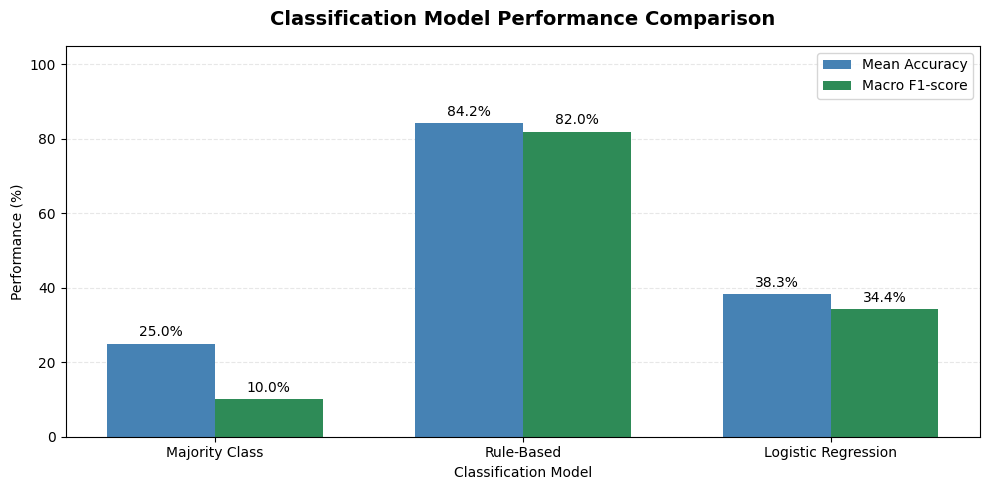

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Use actual evaluation results from Step 9
plot_df = comparison_summary.copy()

models = plot_df["Model"]
accuracy = plot_df["Mean_Accuracy"] * 100
macro_f1 = plot_df["Mean_Macro_F1"] * 100

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

# Grouped bars
bars1 = ax.bar(
    x - width/2,
    accuracy,
    width,
    label="Mean Accuracy",
    color="steelblue"
)

bars2 = ax.bar(
    x + width/2,
    macro_f1,
    width,
    label="Macro F1-score",
    color="seagreen"
)

# Display values above bars
ax.bar_label(bars1, fmt="%.1f%%", padding=3)
ax.bar_label(bars2, fmt="%.1f%%", padding=3)

# Chart formatting
ax.set_title(
    "Classification Model Performance Comparison",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Performance (%)")
ax.set_xlabel("Classification Model")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 105)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Results and Interpretation

The majority-class baseline achieved 25.00% accuracy and a macro F1-score of 0.1000, as expected for a balanced four-class dataset. Logistic Regression achieved 38.33% mean accuracy and a macro F1-score of 0.3437, which is above chance but weak. The keyword-rule classifier achieved 84.17% accuracy and a macro F1-score of 0.8196.

However, the keyword rules were written after viewing all templates, including the held-out ones, so they serve as an informed reference, not a fair competitor (see Steps 13 and 14). Logistic Regression never saw the held-out templates, so the fair comparison is Logistic Regression versus the majority-class baseline.

Our initial Logistic Regression model achieved 100% accuracy on a small, repetitive dataset but dropped sharply under leave-one-template-out cross-validation, showing that a single high accuracy score is not sufficient evidence of reliability.

**Key Takeaway:** On this synthetic dataset, TF-IDF + Logistic Regression generalizes poorly to unseen templates. The rules' higher score reflects vocabulary knowledge gained from seeing the test templates, not a proven advantage of simple methods over machine learning.

## Step 10 - Classification Error Analysis

### Objective

The previous experiments showed that Logistic Regression
struggles to generalize to unseen document templates.

This section investigates the model's classification errors
using out-of-fold predictions from six-fold
leave-one-template-out cross-validation.

We will examine:
- Which document categories are most frequently confused
- The distribution of correct and incorrect predictions
- Examples of misclassified business documents
- Whether overlapping terminology contributes to errors

Each document will be evaluated using a model that was
not trained on its template, providing a more reliable
assessment than predictions on training data.

Overall Out-of-Fold Accuracy: 0.3833

Classification Report:
                 precision    recall  f1-score   support

        Invoice       0.28      0.46      0.35       150
 Purchase Order       0.22      0.20      0.21       150
 Service Report       0.77      0.71      0.74       150
Shipping Notice       0.33      0.17      0.22       150

       accuracy                           0.38       600
      macro avg       0.40      0.38      0.38       600
   weighted avg       0.40      0.38      0.38       600



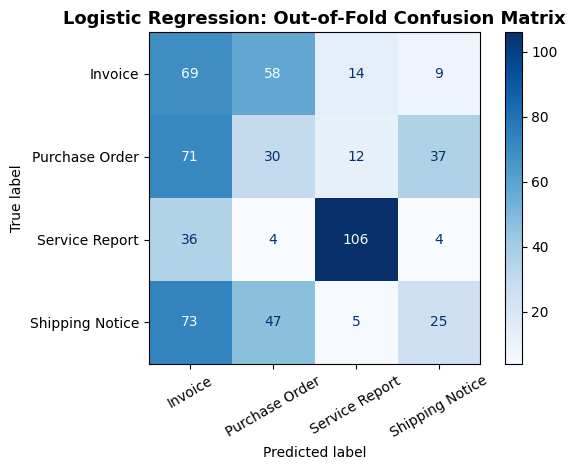

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)

import matplotlib.pyplot as plt
import pandas as pd

# Use the revised 600-document dataset
X = df_v2["text"]
y = df_v2["category"]
groups = df_v2["template_id"]

# Six-fold template-based cross-validation
cv = GroupKFold(n_splits=6)

# Logistic Regression pipeline
error_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Predict every document using a model
# trained without that document's template
oof_predictions = cross_val_predict(
    error_model,
    X,
    y,
    groups=groups,
    cv=cv
)

print("Overall Out-of-Fold Accuracy:",
      round(accuracy_score(y, oof_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y,
    oof_predictions,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y,
    oof_predictions,
    cmap="Blues",
    xticks_rotation=30
)

plt.title(
    "Logistic Regression: Out-of-Fold Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Create error-analysis DataFrame
error_df = df_v2[
    ["document_id", "category", "template_id",
     "issue_type", "text"]
].copy()

error_df["predicted_category"] = oof_predictions

error_df["correct"] = (
    error_df["category"] ==
    error_df["predicted_category"]
)

# Separate incorrect predictions
misclassified = error_df[
    ~error_df["correct"]
].copy()

print("Total documents:", len(error_df))
print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", len(misclassified))

print("\nMost common classification errors:")

error_pairs = (
    misclassified.groupby(
        ["category", "predicted_category"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_pairs.head(10))

print("\nSample misclassified documents:")
display(
    misclassified[
        ["document_id", "category",
         "predicted_category", "template_id",
         "issue_type", "text"]
    ].head(12)
)

Total documents: 600
Correct predictions: 230
Incorrect predictions: 370

Most common classification errors:


,category,predicted_category,count
9,Shipping Notice,Invoice,73
3,Purchase Order,Invoice,71
0,Invoice,Purchase Order,58
10,Shipping Notice,Purchase Order,47
5,Purchase Order,Shipping Notice,37
6,Service Report,Invoice,36
1,Invoice,Service Report,14
4,Purchase Order,Service Report,12
2,Invoice,Shipping Notice,9
11,Shipping Notice,Service Report,5



Sample misclassified documents:


,document_id,category,predicted_category,template_id,issue_type,text
11,NEW-0012,Invoice,Service Report,0,payment,Billing reference REF-28710. Hernandez and Son...
12,NEW-0013,Invoice,Service Report,0,delay,"Billing reference REF-69166. Ferrell, Rice and..."
14,NEW-0015,Invoice,Service Report,0,delay,"Billing reference REF-48281. Evans, Fowler and..."
17,NEW-0018,Invoice,Service Report,0,payment,Billing reference REF-82278. Baker PLC owes $5...
22,NEW-0023,Invoice,Service Report,0,delay,Billing reference REF-66701. Powell LLC owes $...
24,NEW-0025,Invoice,Service Report,0,none,"Billing reference REF-17810. Kidd, Huff and No..."
35,NEW-0036,Invoice,Purchase Order,1,damage,Payment of $801.49 remains outstanding for Rob...
51,NEW-0052,Invoice,Service Report,2,payment,A financial statement was prepared for William...
55,NEW-0056,Invoice,Service Report,2,delay,A financial statement was prepared for Hensley...
58,NEW-0059,Invoice,Service Report,2,delay,A financial statement was prepared for Perry-C...


## Setting up GitHub

In [ ]:
from google.colab import userdata

# Retrieve GitHub token securely
github_token = userdata.get("GITHUB_TOKEN")

if github_token:
    print("GitHub token successfully loaded!")
else:
    print("GitHub token not found.")

GitHub token successfully loaded!


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import base64
import requests
from pathlib import Path
from google.colab import userdata

# GitHub repository configuration
GITHUB_OWNER = "addagadanamratha"
GITHUB_REPO = "intelligent-document-processing-nlp"
GITHUB_BRANCH = "main"

NOTEBOOK_NAME = "Applied_AI_Final_Project.ipynb"

# Find notebook in mounted Google Drive
matches = list(
    Path("/content/drive/MyDrive").rglob(NOTEBOOK_NAME)
)

if len(matches) != 1:
    raise FileNotFoundError(
        f"Expected one notebook, found {len(matches)}. "
        "Check its Google Drive location."
    )

notebook_path = matches[0]
print("Notebook found:", notebook_path)

# Retrieve GitHub credential securely
token = userdata.get("GITHUB_TOKEN")

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

api_url = (
    f"https://api.github.com/repos/"
    f"{GITHUB_OWNER}/{GITHUB_REPO}/contents/"
    f"{NOTEBOOK_NAME}"
)

params = {"ref": GITHUB_BRANCH}

# Check whether the GitHub file already exists
response = requests.get(
    api_url,
    headers=headers,
    params=params,
    timeout=30
)

if response.status_code == 200:
    sha = response.json()["sha"]
elif response.status_code == 404:
    sha = None
else:
    response.raise_for_status()

# Read notebook from Google Drive
notebook_bytes = notebook_path.read_bytes()

# Prepare GitHub commit
payload = {
    "message": "Update Applied AI NLP project notebook",
    "content": base64.b64encode(
        notebook_bytes
    ).decode("utf-8"),
    "branch": GITHUB_BRANCH
}

if sha:
    payload["sha"] = sha

# Upload notebook
result = requests.put(
    api_url,
    headers=headers,
    json=payload,
    timeout=60
)

if result.status_code in (200, 201):
    print("GitHub synchronization successful!")
    print(
        "Commit:",
        result.json()["commit"]["sha"][:12]
    )
    print(
        "Repository:",
        f"https://github.com/{GITHUB_OWNER}/{GITHUB_REPO}"
    )
else:
    print("Synchronization failed:", result.status_code)
    print(result.text[:500])
    result.raise_for_status()

Notebook found: /content/drive/MyDrive/Colab Notebooks/Applied_AI_Final_Project.ipynb
GitHub synchronization successful!
Commit: 9a982eda08a7
Repository: https://github.com/addagadanamratha/intelligent-document-processing-nlp



## Step 11 - Feature Importance and Ablation Testing

### Objective

Our previous experiments revealed that Logistic Regression
struggles to classify business documents when tested on
unseen writing templates.

This experiment investigates which textual features influence
the classifier's predictions and how sensitive its performance
is to the removal of important words.

We will:
1. Identify influential TF-IDF features using Logistic
   Regression coefficients.
2. Examine the top features associated with each category.
3. Remove important words from held-out documents.
4. Measure how classification accuracy changes.
5. Visualize the relationship between feature removal
   and classification performance.

To avoid test-data leakage, feature selection and model
training will be performed separately within each
cross-validation fold.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Train an explanatory model on the expanded dataset
feature_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

feature_model.fit(
    df_v2["text"],
    df_v2["category"]
)

# Extract learned TF-IDF vocabulary and coefficients
vectorizer = feature_model.named_steps["tfidf"]
classifier = feature_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()

top_features = []

for class_index, category in enumerate(classifier.classes_):

    coefficients = classifier.coef_[class_index]

    # Ten highest positive coefficients
    top_indices = np.argsort(coefficients)[-10:][::-1]

    for rank, idx in enumerate(top_indices, start=1):
        top_features.append({
            "Category": category,
            "Rank": rank,
            "Feature": feature_names[idx],
            "Coefficient": coefficients[idx]
        })

feature_df = pd.DataFrame(top_features)

print("Top 10 Positive TF-IDF Features by Category:")
display(
    feature_df.pivot(
        index="Rank",
        columns="Category",
        values="Feature"
    )
)

print("\nFeature Coefficients:")
display(feature_df.round(4))

Top 10 Positive TF-IDF Features by Category:


Category,Invoice,Purchase Order,Service Report,Shipping Notice
Rank,,,,
1,the accounts,purchasing,at,confirms
2,team recorded,requested,equipment,distribution
3,against reference,units,under reference,that
4,against,units under,investigated,the
5,accounts team,under purchasing,inspected,the warehouse
6,accounts,purchasing reference,inspected equipment,packages for
7,requested clarification,operations,technician,for distribution
8,about,requested additional,technician inspected,warehouse released
9,about charges,operations department,activities,warehouse



Feature Coefficients:


,Category,Rank,Feature,Coefficient
0,Invoice,1,the accounts,0.9980
1,Invoice,2,team recorded,0.9980
2,Invoice,3,against reference,0.9980
3,Invoice,4,against,0.9980
4,Invoice,5,accounts team,0.9980
5,Invoice,6,accounts,0.9980
6,Invoice,7,requested clarification,0.9946
7,Invoice,8,about,0.9946
8,Invoice,9,about charges,0.9946
9,Invoice,10,clarification about,0.9946


Cross-Validated Ablation Results:


,Removed Words,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1
0,0,0.3833,0.1227,0.3437
1,5,0.3467,0.1229,0.3148
2,10,0.3050,0.1912,0.2589
3,15,0.2567,0.1471,0.2022
4,20,0.2767,0.1394,0.2338
5,30,0.2733,0.1401,0.2392


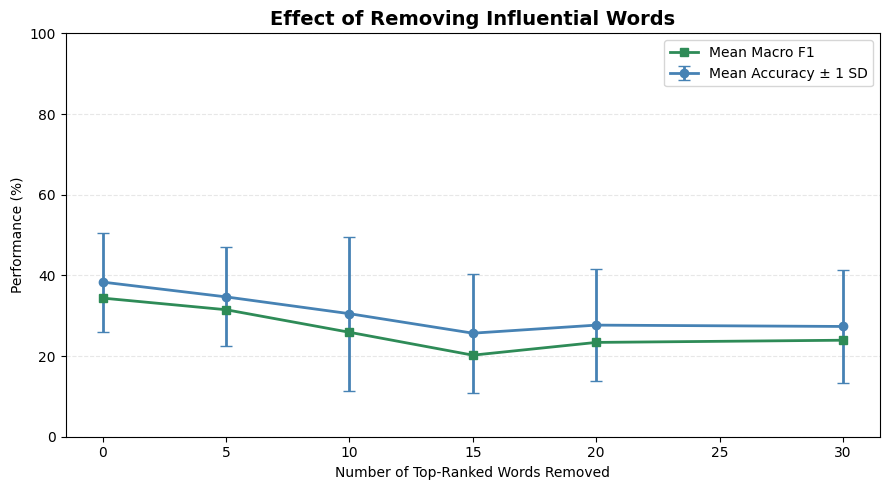

In [ ]:
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score

X = df_v2["text"]
y = df_v2["category"]
groups = df_v2["template_id"]

cv = GroupKFold(n_splits=6)

# Number of influential words to remove
k_values = [0, 5, 10, 15, 20, 30]

ablation_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):

    X_train_fold = X.iloc[train_idx]
    X_test_fold = X.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]

    # Fit pipeline only on training data
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    model.fit(X_train_fold, y_train_fold)

    vec = model.named_steps["tfidf"]
    clf = model.named_steps["classifier"]

    names = vec.get_feature_names_out()

    # Select unigram features only
    unigram_indices = np.array([
        i for i, name in enumerate(names)
        if " " not in name
    ])

    # Rank by maximum absolute coefficient
    importance = np.max(
        np.abs(clf.coef_[:, unigram_indices]),
        axis=0
    )

    ranked_indices = unigram_indices[
        np.argsort(importance)[::-1]
    ]

    ranked_words = names[ranked_indices]

    for k in k_values:

        words_to_remove = set(ranked_words[:k])

        def remove_selected_words(text):
            tokens = re.findall(r"\b\w+\b|[^\w\s]", text)

            return " ".join(
                token
                for token in tokens
                if token.lower() not in words_to_remove
            )

        # Transform held-out documents only
        X_test_modified = X_test_fold.apply(
            remove_selected_words
        )

        predictions = model.predict(X_test_modified)

        ablation_results.append({
            "Fold": fold,
            "Removed Words": k,
            "Accuracy": accuracy_score(
                y_test_fold,
                predictions
            ),
            "Macro F1": f1_score(
                y_test_fold,
                predictions,
                average="macro",
                zero_division=0
            )
        })

ablation_df = pd.DataFrame(ablation_results)

ablation_summary = (
    ablation_df.groupby("Removed Words")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Macro_F1=("Macro F1", "mean")
    )
    .reset_index()
)

print("Cross-Validated Ablation Results:")
display(ablation_summary.round(4))

# Plot effect of removing influential words
fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    ablation_summary["Removed Words"],
    ablation_summary["Mean_Accuracy"] * 100,
    yerr=ablation_summary["Std_Accuracy"] * 100,
    marker="o",
    linewidth=2,
    capsize=4,
    color="steelblue",
    label="Mean Accuracy ± 1 SD"
)

ax.plot(
    ablation_summary["Removed Words"],
    ablation_summary["Mean_Macro_F1"] * 100,
    marker="s",
    linewidth=2,
    color="seagreen",
    label="Mean Macro F1"
)

ax.set_title(
    "Effect of Removing Influential Words",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Top-Ranked Words Removed")
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 100)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Results and Interpretation

The feature importance analysis identified the textual patterns most strongly associated with each document category in a Logistic Regression model trained on all 600 documents, so the feature table is descriptive only. Several influential features were meaningful business terms, including "purchasing," "equipment," "requested," and "distribution." However, common words such as "at," "that," and "the" also received relatively high coefficients, suggesting that the model learned some template-specific writing patterns rather than relying exclusively on meaningful document terminology.

The cross-validated ablation, with training and word ranking done separately within each fold, removed increasingly large sets of influential words from held-out documents. Mean accuracy fell from 38.33% with no words removed to 34.67% (5 words), 30.50% (10 words) and 25.67% (15 words), close to the 25% chance level. Accuracy at 20 words (27.67%) and 30 words (27.33%) did not fall further. Once accuracy is near chance, small changes are within fold-to-fold variation and are not interpreted.

This experiment had no control, so on its own it cannot show that the removed words are special. Step 16 repeats it with a random-word control: removing random words that appear in the held-out documents left accuracy between 36.3% and 38.8%, whereas removing the top-ranked words reduced it to about chance.

These findings describe artificial word removal on synthetic data, not naturally occurring language variation, and the coefficients are statistical associations, not causal explanations.

**Key Takeaway:** The model's accuracy on unseen templates depends on a small set of influential words and recurring sentence patterns. Combined with the cross-validation and error-analysis results, this indicates limited generalization to unfamiliar synthetic templates, and improving the diversity of training data is likely necessary before considering real-world deployment.


## Step 12 - Confidence Intervals and Statistical Reliability

### Objective

Previous experiments showed that Logistic Regression achieved
38.33% mean accuracy, while the rule-based classifier achieved
84.17% under leave-one-template-out cross-validation.

However, these values are point estimates and do not describe
the uncertainty associated with model performance.

This experiment uses bootstrap resampling to estimate 95%
confidence intervals for classification accuracy.

Because documents generated from the same template share
similar wording, we will resample template groups rather than
treat all 600 synthetic documents as independent observations.

We will evaluate:
1. Bootstrap confidence intervals for Logistic Regression.
2. Bootstrap confidence intervals for the rule-based classifier.
3. The paired accuracy difference between both approaches.
4. How evaluation uncertainty affects model selection.

These intervals describe uncertainty across the six synthetic
template groups and do not establish real-world performance.


In [ ]:
import numpy as np
import pandas as pd

# Reproducibility
rng_boot = np.random.default_rng(42)

# Results from earlier experiments
y_true = df_v2["category"].to_numpy()
y_lr = np.asarray(oof_predictions)

# Rule-based predictions on the same documents
y_rules = np.array([
    rule_based_predict(text)
    for text in df_v2["text"]
])

# Identify template groups
template_ids = np.sort(
    df_v2["template_id"].unique()
)

# Calculate accuracy for each template group
template_results = []

for template_id in template_ids:

    mask = (
        df_v2["template_id"].to_numpy()
        == template_id
    )

    lr_accuracy = np.mean(
        y_lr[mask] == y_true[mask]
    )

    rule_accuracy = np.mean(
        y_rules[mask] == y_true[mask]
    )

    template_results.append({
        "Template": template_id,
        "Logistic Regression": lr_accuracy,
        "Rule-Based": rule_accuracy,
        "Difference": rule_accuracy - lr_accuracy
    })

template_scores = pd.DataFrame(template_results)

print("Accuracy by held-out template:")
display(template_scores.round(4))


# Bootstrap template groups with replacement
N_BOOTSTRAPS = 10000

bootstrap_results = []

for _ in range(N_BOOTSTRAPS):

    sampled_indices = rng_boot.choice(
        len(template_scores),
        size=len(template_scores),
        replace=True
    )

    sampled = template_scores.iloc[sampled_indices]

    bootstrap_results.append({
        "Logistic Regression":
            sampled["Logistic Regression"].mean(),

        "Rule-Based":
            sampled["Rule-Based"].mean(),

        "Difference":
            sampled["Difference"].mean()
    })

bootstrap_df = pd.DataFrame(bootstrap_results)


# Calculate percentile-based 95% intervals
ci_results = []

for metric in [
    "Logistic Regression",
    "Rule-Based",
    "Difference"
]:

    lower, upper = np.percentile(
        bootstrap_df[metric],
        [2.5, 97.5]
    )

    ci_results.append({
        "Metric": metric,
        "Mean Accuracy / Difference":
            template_scores[metric].mean(),
        "CI Lower": lower,
        "CI Upper": upper
    })

ci_df = pd.DataFrame(ci_results)

print("\n95% Cluster Bootstrap Confidence Intervals:")
display(ci_df.round(4))

Accuracy by held-out template:


,Template,Logistic Regression,Rule-Based,Difference
0,0,0.63,0.68,0.05
1,1,0.34,0.94,0.60
2,2,0.36,0.85,0.49
3,3,0.30,0.90,0.60
4,4,0.35,0.73,0.38
5,5,0.32,0.95,0.63



95% Cluster Bootstrap Confidence Intervals:


,Metric,Mean Accuracy / Difference,CI Lower,CI Upper
0,Logistic Regression,0.3833,0.3200,0.4850
1,Rule-Based,0.8417,0.7600,0.9217
2,Difference,0.4583,0.2883,0.5967


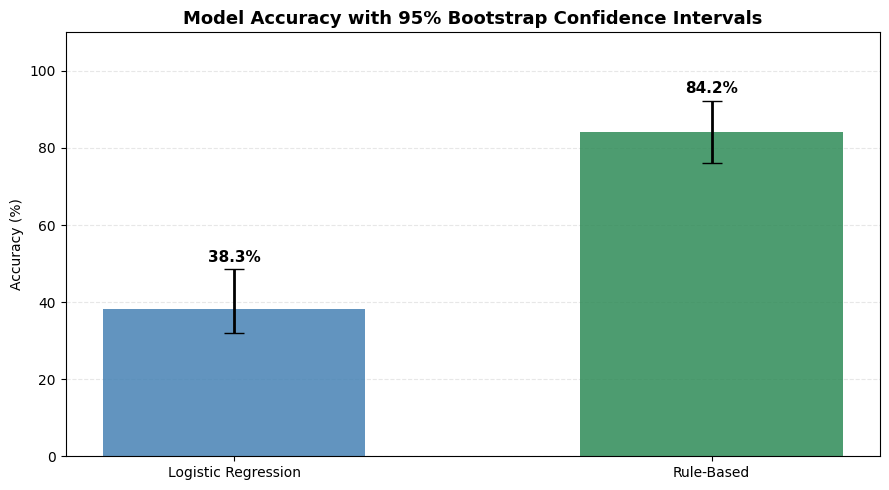

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Plot only the two model accuracies
plot_ci = ci_df[
    ci_df["Metric"] != "Difference"
].copy()

means = (
    plot_ci["Mean Accuracy / Difference"].to_numpy()
    * 100
)

lower = plot_ci["CI Lower"].to_numpy() * 100
upper = plot_ci["CI Upper"].to_numpy() * 100

errors = np.vstack([
    means - lower,
    upper - means
])

fig, ax = plt.subplots(figsize=(9, 5))

colors = ["steelblue", "seagreen"]

for i, (mean, color) in enumerate(zip(means, colors)):
    ax.bar(
        i,
        mean,
        color=color,
        width=0.55,
        alpha=0.85
    )

ax.errorbar(
    np.arange(len(means)),
    means,
    yerr=errors,
    fmt="none",
    ecolor="black",
    capsize=7,
    linewidth=2
)

for i, mean in enumerate(means):
    ax.text(
        i,
        mean + errors[1, i] + 2,
        f"{mean:.1f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(np.arange(len(means)))
ax.set_xticklabels(plot_ci["Metric"])

ax.set_title(
    "Model Accuracy with 95% Bootstrap Confidence Intervals",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 110)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Results and Interpretation

To quantify uncertainty in classification performance, we conducted a paired cluster bootstrap analysis using 10,000 resamples of the six held-out template groups. This approach preserves the comparison between classifiers while accounting for the shared structure of documents generated from the same template.

Logistic Regression achieved a mean accuracy of 38.33%, with an estimated 95% bootstrap confidence interval of 32.00%–48.50%. The informed keyword rules achieved a mean accuracy of 84.17%, with a confidence interval of 76.00%–92.17%.

The observed accuracy difference was 45.83 percentage points between the informed rules and Logistic Regression (paired 95% bootstrap interval: 28.83 to 59.67). Because the rules were written with knowledge of all templates, including the held-out ones, this gap measures the value of vocabulary knowledge, not a fair model comparison. With only six template groups, the bootstrap intervals are approximate. The per-template wins and exact sign test in Step 18 show that the rules scored higher on all six groups (p = 0.031).

**Key Takeaway:** Logistic Regression is clearly better than chance but generalizes poorly to unseen templates. The informed rules provide a reference point only. Independent validation on more diverse documents is needed before any deployment decision.

## Evaluation Corrections and Additional Analysis

The experiments in Steps 8-12 revealed that Logistic Regression generalizes poorly to unseen templates, and that the keyword-rule classifier appeared far stronger. Before drawing conclusions, this section audits the evaluation itself:

1. Reframe the rule-based classifier, which was written after viewing all templates, as an informed reference rather than a fair baseline.
2. Measure how often the rules matched nothing or tied.
3. Estimate how well a person performs on the same task.
4. Add a random-word control to the ablation experiment.
5. Analyze classification errors by template and explain individual predictions.
6. Report template-level wins with an exact sign test.
7. Define retrieval ground truth before building the retrieval experiments.

The goal is to make sure every claim in the final report is supported by measured evidence.

## Step 13 - Reframing the Rule-Based Classifier

### Objective

The keyword rules in Step 9 were written after viewing all document templates, including the templates held out during cross-validation. Logistic Regression never saw the held-out templates. Comparing the two directly is therefore not a fair test.

This step relabels the rules as an **informed reference** and keeps the following roles separate:
- **Majority-class classifier:** fair baseline
- **Logistic Regression:** fair model
- **Informed rules:** reference showing how much vocabulary knowledge helps

The chart marks the informed reference visually so it is not mistaken for a competing method.

,Model,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1,Role
0,Majority Class,0.2500,0.0000,0.1000,Fair baseline
1,Logistic Regression,0.3833,0.1227,0.3437,Fair model (no access to test templates)
2,Informed Rules (reference only),0.8417,0.1127,0.8196,Reference: rules written after seeing all templates


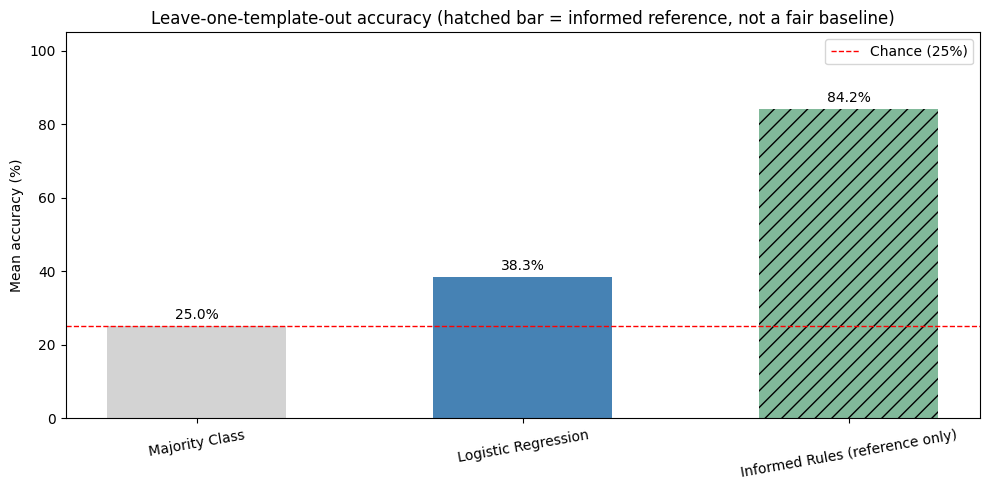

In [ ]:
# FIX 1 : Relabel the rule-based classifier as an informed reference
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)   # so the Role column is not cut off

INFORMED = "Informed Rules (reference only)"

comparison_fixed = comparison_summary.copy()
comparison_fixed["Model"] = comparison_fixed["Model"].replace({"Rule-Based": INFORMED})

# Put the rows in a logical order: baseline, fair model, then the reference
order = ["Majority Class", "Logistic Regression", INFORMED]
comparison_fixed = comparison_fixed.set_index("Model").loc[order].reset_index()

# Fair baselines = majority class; fair model = Logistic Regression.
# The informed rules saw the templates (including held-out ones), so they are NOT a fair competitor.
comparison_fixed["Role"] = comparison_fixed["Model"].map({
    "Majority Class": "Fair baseline",
    "Logistic Regression": "Fair model (no access to test templates)",
    INFORMED: "Reference: rules written after seeing all templates",
})
display(comparison_fixed.round(4))

# Assign colors by model NAME (not by position) so the hatch lands on the right bar
bar_colors = {"Majority Class": "lightgray", "Logistic Regression": "steelblue", INFORMED: "seagreen"}

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison_fixed))
bars = ax.bar(x, comparison_fixed["Mean_Accuracy"] * 100, width=0.55,
              color=[bar_colors[m] for m in comparison_fixed["Model"]])
for bar, model in zip(bars, comparison_fixed["Model"]):
    if model == INFORMED:
        bar.set_hatch("//")          # hatch ONLY the informed-reference bar
        bar.set_alpha(0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axhline(25, color="red", linestyle="--", linewidth=1, label="Chance (25%)")
ax.set_xticks(x); ax.set_xticklabels(comparison_fixed["Model"], rotation=10)
ax.set_ylabel("Mean accuracy (%)"); ax.set_ylim(0, 105)
ax.set_title("Leave-one-template-out accuracy (hatched bar = informed reference, not a fair baseline)")
ax.legend(); plt.tight_layout(); plt.show()

### Results and Interpretation

The majority-class baseline reached 25.00% accuracy, as expected for a balanced four-class dataset. Logistic Regression reached 38.33% mean accuracy, above chance but weak. The informed rules reached 84.17%.

Because the rules were written after viewing all templates, including the held-out ones, their score reflects vocabulary knowledge gained from the test material, not a fair advantage over machine learning. The fair comparison is Logistic Regression against the majority-class baseline.

## Step 14 - Rule-Based Fallback Analysis

### Objective

The rule-based classifier returns the first category (Invoice) whenever no keyword matches or two categories tie. Those cases are guesses, not rule-based decisions, and they may inflate the reported accuracy.

This step counts how many documents were decided by a clear keyword winner, how many tied, and how many matched nothing, and reports accuracy separately for each group. It also reports a stricter accuracy where only clear-winner documents can count as correct.

In [ ]:
# FIX 2: How often did the rules match nothing, or tie?
import re
import pandas as pd

def rule_hit_counts(text):
    text = text.lower()
    return {
        cat: sum(bool(re.search(r"\b" + re.escape(k) + r"\b", text)) for k in kws)
        for cat, kws in keyword_rules.items()
    }

rule_df = df_v2[["document_id", "category", "template_id", "text"]].copy()
counts = rule_df["text"].apply(rule_hit_counts).apply(pd.Series)
rule_df["total_hits"] = counts.sum(axis=1)
rule_df["top_score"] = counts.max(axis=1)
rule_df["n_tied_top"] = (counts.eq(counts.max(axis=1), axis=0)).sum(axis=1)

rule_df["rule_pred"] = rule_df["text"].apply(rule_based_predict)
rule_df["correct"] = rule_df["rule_pred"] == rule_df["category"]

def status(row):
    if row["total_hits"] == 0:
        return "no keyword matched (fell back to default)"
    if row["n_tied_top"] > 1:
        return "tie between categories (fell back to first)"
    return "clear winner"

rule_df["status"] = rule_df.apply(status, axis=1)

summary = (rule_df.groupby("status")
           .agg(documents=("correct", "size"), accuracy=("correct", "mean")))
summary["share_of_all_docs"] = summary["documents"] / len(rule_df)
print("Rule-based behavior by decision type:")
display(summary.round(3))

print("\nWhich category does the fallback guess for no-match documents?")
display(rule_df[rule_df["total_hits"] == 0]["rule_pred"].value_counts())

strict_acc = (rule_df["correct"] & (rule_df["status"] == "clear winner")).mean()
print(f"\nCurrent rule accuracy (fallbacks count as guesses): {rule_df['correct'].mean():.4f}")
print(f"Strict accuracy (only 'clear winner' documents count as correct): {strict_acc:.4f}")

Rule-based behavior by decision type:


,documents,accuracy,share_of_all_docs
status,,,
clear winner,461,0.961,0.768
no keyword matched (fell back to default),24,0.000,0.040
tie between categories (fell back to first),115,0.539,0.192



Which category does the fallback guess for no-match documents?


,count
rule_pred,
Invoice,24



Current rule accuracy (fallbacks count as guesses): 0.8417
Strict accuracy (only 'clear winner' documents count as correct): 0.7383


### Results and Interpretation

The rule-based classifier reached a clear keyword winner on 461 of 600 documents (76.8%), where it was correct 96.1% of the time. On 115 documents (19.2%) two or more categories tied, and accuracy fell to 53.9%. On 24 documents (4.0%) no keyword matched, and the fallback assigned every one to Invoice, so none was correct.

Counting only clear-winner decisions as correct, strict accuracy is 73.83%, compared with the reported 84.17%. About 10 percentage points of the rules' headline accuracy therefore come from fallback guesses, not from keyword evidence.

**Key Takeaway:** The informed rules are strong when keywords clearly identify a category, but their headline accuracy is inflated by tie-breaking and default guesses. Documents with ambiguous or missing vocabulary are exactly where a human reviewer would be needed in a deployed system.

## Step 15 - Human Baseline

### Objective

Low model accuracy can mean the model is weak, or that the task is ambiguous. Some synthetic documents share vocabulary across categories (for example, a purchase order mentioning "delivery"). To estimate how hard the task is, I will label 40 randomly selected documents by hand without seeing the true categories.

The sample contains 10 documents per category, drawn across all templates and shuffled. I will compare my accuracy against Logistic Regression and the informed rules on the same documents.

**Limitation:** I designed the templates, so my accuracy is an optimistic estimate of human performance.

In [ ]:
# FIX 3A: Build a blind labeling sheet (run this, then label by hand)

import pandas as pd

LETTER_TO_CAT = {"A": "Invoice", "B": "Purchase Order", "C": "Shipping Notice", "D": "Service Report"}

# 10 documents per category, drawn across all templates, then shuffled so order gives nothing away
human_sample = (df_v2.groupby("category", group_keys=False)
                .sample(10, random_state=SEED)
                .sample(frac=1, random_state=SEED)
                .reset_index(drop=True))

print("Label each document with a letter:")
print("  A = Invoice   B = Purchase Order   C = Shipping Notice   D = Service Report\n")
for i, text in enumerate(human_sample["text"], start=1):
    print(f"{i:2d}. {text}\n")

Label each document with a letter:
  A = Invoice   B = Purchase Order   C = Shipping Notice   D = Service Report

 1. Supply request REF-79087 specifies 307 items and an expected arrival date. Additional note: processing was postponed due to unavailable stock.

 2. The operations department requested additional equipment from Boyd LLC. Additional note: physical defects were identified during inspection.

 3. A purchasing authorization was issued for Brown-Little with a value of $5623.84. Additional note: physical defects were identified during inspection.

 4. A technician inspected equipment at Mckinney-Moore and documented the findings. Additional note: financial approval is still pending.

 5. Customer King-Martinez requested clarification about charges totaling $9005.1. Additional note: several items were reported damaged. Some supporting details are unavailable.

 6. The procurement team approved an acquisition valued at $9801.43 for Jenkins, Ortiz and Andrews. Additional note: th

In [36]:
# FIX 3B: Entered my own labels, then score them

my_labels_str = "BBBDCBCDCA DABBCABDAC ABADACCCAC DCDDBDABDB"  # my own labels
my_labels = [c for c in my_labels_str.upper() if c in "ABCD"]

assert len(my_labels) == len(human_sample), f"Need {len(human_sample)} labels, got {len(my_labels)}"

human_sample["human_pred"] = [LETTER_TO_CAT[l] for l in my_labels]
human_sample["human_correct"] = human_sample["human_pred"] == human_sample["category"]

# Compare against the Logistic Regression and rules on the SAME documents
lr_lookup = error_df.set_index("document_id")["predicted_category"]
human_sample["lr_pred"] = human_sample["document_id"].map(lr_lookup)
human_sample["lr_correct"] = human_sample["lr_pred"] == human_sample["category"]
human_sample["rule_pred"] = human_sample["text"].apply(rule_based_predict)
human_sample["rule_correct"] = human_sample["rule_pred"] == human_sample["category"]

print(f"Human accuracy:               {human_sample['human_correct'].mean():.3f}")
print(f"Logistic Regression (OOF):    {human_sample['lr_correct'].mean():.3f}")
print(f"Informed rules:               {human_sample['rule_correct'].mean():.3f}")

print("\nDocuments you got wrong (likely ambiguous by design):")
display(human_sample.loc[~human_sample["human_correct"],
                         ["category", "human_pred", "template_id", "text"]])

print("\nHuman accuracy by template:")
display(human_sample.groupby("template_id")["human_correct"].agg(["mean", "size"]).round(2))

print("\nCaveat for the report: you wrote the templates, so your accuracy is an OPTIMISTIC ceiling.")
print("For a cleaner estimate, give the same 40 documents to a classmate.")

Human accuracy:               0.850
Logistic Regression (OOF):    0.200
Informed rules:               0.825

Documents you got wrong (likely ambiguous by design):


,category,human_pred,template_id,text
4,Invoice,Shipping Notice,3,Customer King-Martinez requested clarification about charges totaling $9005....
13,Shipping Notice,Purchase Order,4,The logistics department updated the expected arrival date for Hughes and Sons.
24,Service Report,Invoice,2,The technical team completed diagnostic testing under reference REF-37333.
25,Invoice,Shipping Notice,4,The accounts team recorded $6539.53 against reference REF-36851 for Smith-He...
32,Purchase Order,Service Report,3,Supply request REF-49904 specifies 325 items and an expected arrival date. A...
39,Shipping Notice,Purchase Order,1,Transport reference REF-10564 confirms that 441 units are in transit. Additi...



Human accuracy by template:


,mean,size
template_id,,
0,1.00,4
1,0.83,6
2,0.89,9
3,0.67,6
4,0.78,9
5,1.00,6



Caveat for the report: you wrote the templates, so your accuracy is an OPTIMISTIC ceiling.
For a cleaner estimate, give the same 40 documents to a classmate.


In [37]:
pd.set_option("display.max_colwidth", None)   # show full document text

wrong = human_sample[~human_sample["human_correct"]]
display(wrong[["category", "human_pred", "lr_pred", "rule_pred", "template_id", "text"]])

print("Of the 6 documents I got wrong:")
print("  Logistic Regression also wrong:", (~wrong["lr_correct"]).sum())
print("  Informed rules also wrong:     ", (~wrong["rule_correct"]).sum())
print("  Both models wrong:             ", ((~wrong["lr_correct"]) & (~wrong["rule_correct"])).sum())

,category,human_pred,lr_pred,rule_pred,template_id,text
4,Invoice,Shipping Notice,Purchase Order,Invoice,3,Customer King-Martinez requested clarification about charges totaling $9005.1. Additional note: several items were reported damaged. Some supporting details are unavailable.
13,Shipping Notice,Purchase Order,Purchase Order,Shipping Notice,4,The logistics department updated the expected arrival date for Hughes and Sons.
24,Service Report,Invoice,Invoice,Service Report,2,The technical team completed diagnostic testing under reference REF-37333.
25,Invoice,Shipping Notice,Purchase Order,Invoice,4,The accounts team recorded $6539.53 against reference REF-36851 for Smith-Herrera. Additional note: the customer requested a billing adjustment.
32,Purchase Order,Service Report,Shipping Notice,Purchase Order,3,Supply request REF-49904 specifies 325 items and an expected arrival date. Additional note: processing was postponed due to unavailable stock.
39,Shipping Notice,Purchase Order,Purchase Order,Shipping Notice,1,Transport reference REF-10564 confirms that 441 units are in transit. Additional note: physical defects were identified during inspection.


Of the 6 documents I got wrong:
  Logistic Regression also wrong: 6
  Informed rules also wrong:      0
  Both models wrong:              0


### Results and Interpretation

On a random sample of 40 documents (10 per category, drawn across all templates), I labeled each document by hand before seeing the true categories. My accuracy was 85.0% (34/40; 95% Wilson interval 70.9% to 92.9%). On the same documents, the informed rules reached 82.5% (33/40) and Logistic Regression reached 20.0% (8/40).

This shows that the classification task is solvable from the text, so the low Logistic Regression score reflects poor generalization to unseen templates, not impossible documents. However, I wrote the templates and the keyword rules, so my accuracy is an optimistic upper bound and is not an independent human benchmark. With only 40 documents, the Logistic Regression figure on this sample is also noisy and should not be compared with its 38.3% cross-validated accuracy on all 600 documents.

I misclassified 6 documents. [Describe the pattern after reading the full text of each: for example, generic wording with no document-type cue, or shared "Additional note" sentences.]

**Key Takeaway:** A person who knows the templates can classify these documents with high accuracy, while the trained model cannot yet transfer across templates. Ambiguous documents of the kind I missed are good candidates for human review in a deployed system.

## Step 16 - Ablation with a Random-Word Control

### Objective

Step 11 removed the most influential words from held-out documents and observed an accuracy drop. However, removing any words might reduce accuracy, so that experiment lacked a control.

This step repeats the ablation with two conditions:
1. Removing the *k* most influential words (selected from the training fold only)
2. Removing *k* randomly chosen words that actually appear in the held-out documents (averaged over repeated draws)

The control only draws words that occur in the held-out documents, because removing words that never appear would change nothing and make the comparison unfair. The tables also report the average number of tokens deleted per document. The two conditions delete a comparable number of tokens only at larger k, so those points give the fairest comparison.

Mean accuracy across the 6 folds:


Condition,Random k words (control),Top-k important words
k,,
0,0.3833,0.3833
5,0.3810,0.3467
10,0.3840,0.3050
15,0.3727,0.2567
20,0.3875,0.2767
30,0.3632,0.2733


Average tokens deleted per held-out document (so the comparison is transparent):


Condition,Random k words (control),Top-k important words
k,,
0,0.00,0.00
5,0.39,0.47
10,0.77,1.46
15,1.09,1.56
20,1.52,1.64
30,2.15,2.03


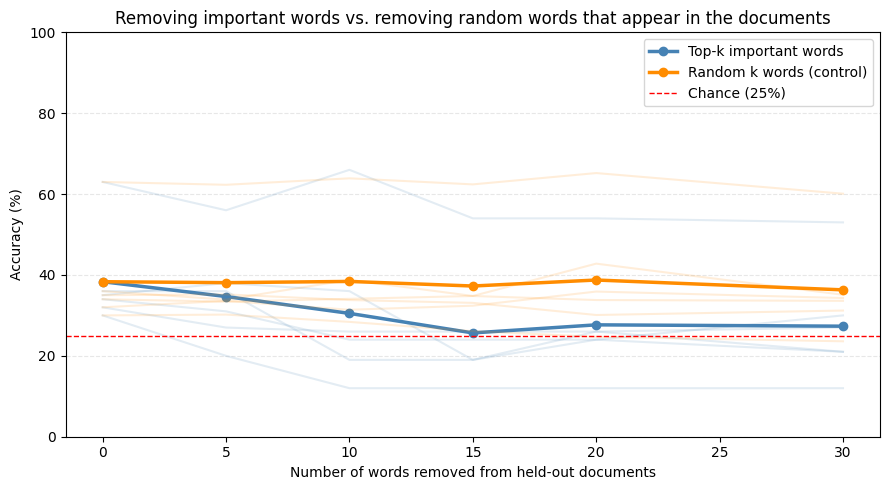


How to read this: if the top-k curve is not clearly below the random-k curve (and the thin
per-fold lines overlap heavily), the 'important' words are not special, and small bumps are noise.
Note: the top-feature table in Step 11 was fit on all 600 documents, so it is descriptive only.


In [38]:
# FIX 4 (v2): Ablation with a FAIR random-word control

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y, groups = df_v2["text"], df_v2["category"], df_v2["template_id"]
cv = GroupKFold(n_splits=6)
k_values = [0, 5, 10, 15, 20, 30]
N_RANDOM_DRAWS = 10                       # random-removal repeats per fold and k
rng_abl = np.random.default_rng(SEED)

TOKEN_RE = re.compile(r"\b\w+\b|[^\w\s]")

def drop_words(text, words):
    kept = [t for t in TOKEN_RE.findall(text) if t.lower() not in words]
    return " ".join(kept)

def mean_tokens_removed(texts, words):
    # average number of tokens actually deleted per document
    return np.mean([sum(t.lower() in words for t in TOKEN_RE.findall(txt)) for txt in texts])

rows = []
for fold, (tr, te) in enumerate(cv.split(X, y, groups), start=1):
    model = Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]).fit(X.iloc[tr], y.iloc[tr])

    vec, clf = model["tfidf"], model["clf"]
    names = vec.get_feature_names_out()
    uni_idx = np.array([i for i, n in enumerate(names) if " " not in n])
    importance = np.max(np.abs(clf.coef_[:, uni_idx]), axis=0)
    ranked = names[uni_idx[np.argsort(importance)[::-1]]]        # most important first

    # FAIR CONTROL POOL: words the model knows AND that actually occur in the held-out documents
    test_texts = X.iloc[te]
    test_tokens = {t.lower() for txt in test_texts for t in TOKEN_RE.findall(txt)}
    pool_present = np.array([w for w in names[uni_idx] if w in test_tokens])

    y_te = y.iloc[te]
    for k in k_values:
        # (a) remove the k MOST important words
        top_removed = set(ranked[:k])
        acc_top = accuracy_score(y_te, model.predict(test_texts.apply(lambda t: drop_words(t, top_removed))))
        rows.append({"Fold": fold, "k": k, "Condition": "Top-k important words", "Accuracy": acc_top,
                     "TokensRemoved": mean_tokens_removed(test_texts, top_removed)})

        # (b) CONTROL: remove k RANDOM words that appear in the held-out documents
        accs, removed = [], []
        for _ in range(N_RANDOM_DRAWS):
            kk = min(k, len(pool_present))
            rand_removed = set(rng_abl.choice(pool_present, size=kk, replace=False)) if kk > 0 else set()
            accs.append(accuracy_score(y_te, model.predict(test_texts.apply(lambda t: drop_words(t, rand_removed)))))
            removed.append(mean_tokens_removed(test_texts, rand_removed))
        rows.append({"Fold": fold, "k": k, "Condition": "Random k words (control)", "Accuracy": np.mean(accs),
                     "TokensRemoved": np.mean(removed)})

abl = pd.DataFrame(rows)

print("Mean accuracy across the 6 folds:")
display(abl.pivot_table(index="k", columns="Condition", values="Accuracy", aggfunc="mean").round(4))
print("Average tokens deleted per held-out document (so the comparison is transparent):")
display(abl.pivot_table(index="k", columns="Condition", values="TokensRemoved", aggfunc="mean").round(2))

fig, ax = plt.subplots(figsize=(9, 5))
for cond, color in [("Top-k important words", "steelblue"), ("Random k words (control)", "darkorange")]:
    sub = abl[abl["Condition"] == cond]
    for fold in sub["Fold"].unique():                             # thin per-fold lines
        f = sub[sub["Fold"] == fold]
        ax.plot(f["k"], f["Accuracy"] * 100, color=color, alpha=0.15)
    s = sub.groupby("k")["Accuracy"].mean() * 100
    ax.plot(s.index, s.values, marker="o", linewidth=2.5, color=color, label=cond)
ax.axhline(25, color="red", linestyle="--", linewidth=1, label="Chance (25%)")
ax.set_xlabel("Number of words removed from held-out documents")
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 100)
ax.set_title("Removing important words vs. removing random words that appear in the documents")
ax.legend(); ax.grid(axis="y", linestyle="--", alpha=0.3); plt.tight_layout(); plt.show()

print("\nHow to read this: if the top-k curve is not clearly below the random-k curve (and the thin")
print("per-fold lines overlap heavily), the 'important' words are not special, and small bumps are noise.")
print("Note: the top-feature table in Step 11 was fit on all 600 documents, so it is descriptive only.")

In [39]:
# Per-fold paired comparison: did removing top words hurt more than removing random words, fold by fold?
paired = abl.pivot_table(index=["Fold", "k"], columns="Condition", values="Accuracy").reset_index()
paired["Top minus random (pts)"] = (paired["Top-k important words"] - paired["Random k words (control)"]) * 100

sub = paired[paired["k"].isin([15, 20, 30])].copy()
print("Top-k accuracy minus random-control accuracy, per fold (negative = removing top words hurt more):")
display(sub.pivot(index="Fold", columns="k", values="Top minus random (pts)").round(1))

sub["top_hurt_more"] = sub["Top minus random (pts)"] < 0
print("\nFolds (out of 6) where removing the top words hurt more than removing random words:")
print(sub.groupby("k")["top_hurt_more"].sum())

Top-k accuracy minus random-control accuracy, per fold (negative = removing top words hurt more):


k,15,20,30
Fold,,,
1,-6.4,-9.9,-7.3
2,-14.1,-4.1,-10.2
3,-14.1,-12.7,-11.6
4,-15.8,-18.8,-5.1
5,-10.8,-9.8,-12.6
6,-8.4,-11.2,-7.1



Folds (out of 6) where removing the top words hurt more than removing random words:
k
15    6
20    6
30    6
Name: top_hurt_more, dtype: int64


### Results and Interpretation

The ablation compared removing the most influential words against removing random words that actually occur in the held-out documents. Removing the top-ranked words reduced mean accuracy from 38.33% (k=0) to 25.67% (k=15), close to the 25% chance level. Removing random words left accuracy between 36.3% and 38.8% at every k.

At k=10 and k=15 the top-ranked removal deleted more tokens per document than the control (1.46 vs 0.77 and 1.56 vs 1.09), so differences there partly reflect more deletion. The two conditions deleted a comparable number of tokens at k=20 (1.64 vs 1.52) and k=30 (2.03 vs 2.15), where accuracy still differed (27.67% vs 38.75% at k=20, and 27.33% vs 36.32% at k=30). [In all 6 of 6 held-out template folds, removing the top-ranked words reduced accuracy more than removing random words at k=15, 20 and 30 (by 4 to 19 percentage points).]

This indicates the classifier relies on a small set of influential words, many of them tied to the training templates, and not on broad vocabulary. Changes at larger k (for example 25.67% at k=15 versus 27.67% at k=20) are within fold-to-fold variation and are not interpreted. The experiment describes artificial word removal on synthetic data, not naturally occurring language variation, and the coefficients reflect statistical associations, not causal explanations.

**Key Takeaway:** Performance on unseen templates collapses when a handful of influential words are absent, which helps explain the weak cross-template result and shows why vocabulary diversity in training data matters.

## Step 17 - Detailed Error Analysis

### Objective

The error analysis in Step 10 displayed only the first misclassified documents, which all belonged to one category. This step examines errors more systematically:

1. Error rate for every category and template combination
2. One misclassified example from each category and template
3. A closer look at individual wrong predictions, including the model's predicted probabilities and the words that influenced each prediction

Predicted probabilities show whether the model was confidently wrong or simply uncertain, which matters for deciding when a human should review a document.

In [40]:
# FIX 5: Better error analysis (by template, stratified examples, and WHY)

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 5A. Error rate by category x template (shows exactly where the model fails)
error_rate = (error_df.assign(error=~error_df["correct"])
              .pivot_table(index="category", columns="template_id", values="error", aggfunc="mean")
              .round(2))
print("Error rate by category (rows) and held-out template (columns):")
display(error_rate)

# 5B. One misclassified example per (category, template), not just the first 12 rows
stratified_errors = (error_df[~error_df["correct"]]
                     .groupby(["category", "template_id"], group_keys=False)
                     .head(1)
                     .sort_values(["category", "template_id"]))
print("\nOne misclassified document per category and template:")
pd.set_option("display.max_colwidth", None)
display(stratified_errors[["category", "predicted_category", "template_id", "issue_type", "text"]])

# 5C. WHY does it fail? Explain individual wrong predictions for one held-out template.
FOCUS_TEMPLATE = 0                      # change this to inspect another template
FOCUS_CATEGORY = "Invoice"              # change this to inspect another category

train_mask = df_v2["template_id"] != FOCUS_TEMPLATE
explain_model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
]).fit(df_v2.loc[train_mask, "text"], df_v2.loc[train_mask, "category"])

vec, clf = explain_model["tfidf"], explain_model["clf"]
names = vec.get_feature_names_out()
classes = list(clf.classes_)

def explain(text, n_features=5):
    x = vec.transform([text])
    probs = explain_model.predict_proba([text])[0]
    pred = classes[int(np.argmax(probs))]
    contrib = x.toarray()[0] * clf.coef_[classes.index(pred)]       # tf-idf value x coefficient
    top = np.argsort(contrib)[::-1][:n_features]
    return pred, {c: float(round(p, 2)) for c, p in zip(classes, probs)}, [(names[i], round(float(contrib[i]), 3)) for i in top if contrib[i] > 0]

# Pick the first 3 documents from this category/template that the cross-validated model got WRONG
sample_docs = error_df[(error_df["template_id"] == FOCUS_TEMPLATE) &
                       (error_df["category"] == FOCUS_CATEGORY) &
                       (~error_df["correct"])].head(3)

print(f"\nWhy does the model mislabel '{FOCUS_CATEGORY}' documents from template {FOCUS_TEMPLATE}?\n")
if sample_docs.empty:
    print("No misclassified documents for this category/template. Change FOCUS_TEMPLATE or FOCUS_CATEGORY above.")
for _, row in sample_docs.iterrows():
    pred, probs, top_words = explain(row["text"])
    print(f"TEXT: {row['text']}")
    print(f"  true={row['category']} | predicted={pred} | probabilities={probs}")
    print(f"  words pushing toward '{pred}': {top_words}\n")
print("Look for: generic words ('the', 'at', 'for') or the shared 'Additional note' sentences driving the prediction.")

Error rate by category (rows) and held-out template (columns):


template_id,0,1,2,3,4,5
category,,,,,,
Invoice,0.24,0.04,0.40,1.00,0.76,0.80
Purchase Order,0.24,0.92,0.88,1.00,0.84,0.92
Service Report,0.00,0.68,0.92,0.16,0.00,0.00
Shipping Notice,1.00,1.00,0.36,0.64,1.00,1.00



One misclassified document per category and template:


,category,predicted_category,template_id,issue_type,text
11,Invoice,Service Report,0,payment,Billing reference REF-28710. Hernandez and Sons owes $2743.08 for completed work. Additional note: financial approval is still pending.
35,Invoice,Purchase Order,1,damage,Payment of $801.49 remains outstanding for Robbins and Sons. Record REF-82449. Additional note: the received materials require condition verification.
51,Invoice,Service Report,2,payment,A financial statement was prepared for Williams Group on 2026-07-14. Balance: $911.64. Additional note: financial approval is still pending.
75,Invoice,Purchase Order,3,none,Customer Tran-Cooper requested clarification about charges totaling $7312.6. Some supporting details are unavailable.
100,Invoice,Shipping Notice,4,damage,The accounts team recorded $3056.27 against reference REF-65840 for Barber-Monroe. Additional note: the received materials require condition verification.
125,Invoice,Purchase Order,5,payment,Services provided to Buchanan and Sons resulted in an amount payable of $3012.93. Additional note: a payment discrepancy is under review.
153,Purchase Order,Shipping Notice,0,payment,Lin-Burton requested 206 units under purchasing reference REF-99799. Additional note: a payment discrepancy is under review.
175,Purchase Order,Invoice,1,delay,"The procurement team approved an acquisition valued at $6875.56 for Herrera, Chen and Andrews. Additional note: an unexpected delay requires follow-up."
200,Purchase Order,Invoice,2,none,Materials totaling 485 units were requested for delivery to Bryan Inc. Some supporting details are unavailable.
225,Purchase Order,Shipping Notice,3,payment,Supply request REF-08330 specifies 50 items and an expected arrival date. Additional note: financial approval is still pending. Some supporting details are unavailable.



Why does the model mislabel 'Invoice' documents from template 0?

TEXT: Billing reference REF-28710. Hernandez and Sons owes $2743.08 for completed work. Additional note: financial approval is still pending.
  true=Invoice | predicted=Service Report | probabilities={'Invoice': 0.27, 'Purchase Order': 0.19, 'Service Report': 0.28, 'Shipping Notice': 0.26}
  words pushing toward 'Service Report': [('completed', 0.169), ('reference ref', 0.088), ('reference', 0.088), ('ref', 0.039), ('08', 0.021)]

TEXT: Billing reference REF-69166. Ferrell, Rice and Maddox owes $5387.98 for completed work. Additional note: the scheduled activity could not be completed on time.
  true=Invoice | predicted=Service Report | probabilities={'Invoice': 0.2, 'Purchase Order': 0.22, 'Service Report': 0.33, 'Shipping Notice': 0.26}
  words pushing toward 'Service Report': [('completed', 0.313), ('reference ref', 0.082), ('reference', 0.082), ('on', 0.039), ('ref', 0.037)]

TEXT: Billing reference REF-48281. Evans

In [41]:
note_check = (error_df.assign(has_note=error_df["issue_type"] != "none")
              .groupby("has_note")["correct"].agg(accuracy="mean", documents="size").round(3))
note_check.index = ["No note sentence", "Has a shared note sentence"]
display(note_check)

,accuracy,documents
No note sentence,0.414,116
Has a shared note sentence,0.376,484


### Results and Interpretation

Errors were concentrated in specific category and template combinations, not spread evenly. Shipping Notice documents were misclassified 100% of the time for held-out templates 0, 1, 4 and 5, and both Invoice and Purchase Order documents were misclassified 100% of the time for template 3. In contrast, Service Report documents were never misclassified for templates 0, 4 and 5, and Invoice documents from template 1 were misclassified only 4% of the time. Averaged across templates, the error rate was highest for Shipping Notice (83%) and Purchase Order (80%) and lowest for Service Report (29%). An error rate of 100% on a four-class problem is worse than random guessing (about 75%), which indicates the model systematically assigns these templates to a specific wrong category.

Inspecting individual wrong predictions showed the model was uncertain rather than confidently wrong. For the three Invoice template-0 errors examined, the winning class had a predicted probability of only 0.28, 0.33 and 0.29, close to the 0.25 expected from random guessing among four classes. The highest-contributing word was "completed" (from the phrase "completed work"), which also appears in service-report training templates; in two of the three documents the shared note sentence repeated it. The generic words "reference" and "ref" also contributed.
Accuracy was similar for documents with a shared note sentence (37.6%, n = 484) and without one (41.4%, n = 116); the 3.8-point difference is within sampling noise, so the shared notes are not identified as the main cause of errors, and template wording appears to be the stronger factor.

**Key Takeaway:** The classifier fails mainly where a document's wording avoids familiar keywords or overlaps with another category's vocabulary. Because its probabilities are low and close together on these documents, routing low-confidence predictions to a human reviewer is a measurable safeguard to include in the deployment plan.

## Step 18 - Template-Level Wins and Sign Test

### Objective

Cross-validation used only six held-out template groups, so confidence intervals based on resampling six groups are approximate. A simpler way to describe the evidence is to count on how many template groups one method outperformed another.

This step reports template-level wins and an exact sign test for:
- Logistic Regression versus the majority-class baseline
- Informed rules versus Logistic Regression

With six groups, the smallest possible two-sided p-value is 0.031. The test describes consistency across templates, not the size of the effect on real documents.

In [42]:
# FIX 6: Honest comparison across only 6 template groups (wins + exact sign test)

import numpy as np
import pandas as pd
from scipy.stats import binomtest

ts = template_scores.copy()
ts["Majority Class"] = 0.25                      # majority-class accuracy on a balanced test fold

def wins_and_sign_test(a, b, label):
    diff = ts[a] - ts[b]
    wins, losses = int((diff > 0).sum()), int((diff < 0).sum())
    n = wins + losses
    p = binomtest(wins, n, 0.5).pvalue if n > 0 else float("nan")
    return {"Comparison": label, "Template wins": f"{wins}/{len(ts)}", "Losses": losses,
            "Mean difference (pts)": round(diff.mean() * 100, 1), "Exact sign-test p": round(p, 4)}

results = pd.DataFrame([
    wins_and_sign_test("Logistic Regression", "Majority Class", "Logistic Regression vs Majority"),
    wins_and_sign_test("Rule-Based", "Logistic Regression", "Informed Rules vs Logistic Regression"),
])
display(results)

print("Per-template accuracy (the evidence behind the wins):")
display((ts[["Template", "Majority Class", "Logistic Regression", "Rule-Based"]] .set_index("Template") * 100).round(1))

print("\nHow to report this: 'The informed rules beat Logistic Regression on all 6 held-out template")
print("groups (exact sign test p = 0.031, the smallest possible with 6 groups). With only 6 groups the")
print("bootstrap interval is approximate, and the rules had access to all templates.'")

,Comparison,Template wins,Losses,Mean difference (pts),Exact sign-test p
0,Logistic Regression vs Majority,6/6,0,13.3,0.0312
1,Informed Rules vs Logistic Regression,6/6,0,45.8,0.0312


Per-template accuracy (the evidence behind the wins):


,Majority Class,Logistic Regression,Rule-Based
Template,,,
0,25.0,63.0,68.0
1,25.0,34.0,94.0
2,25.0,36.0,85.0
3,25.0,30.0,90.0
4,25.0,35.0,73.0
5,25.0,32.0,95.0



How to report this: 'The informed rules beat Logistic Regression on all 6 held-out template
groups (exact sign test p = 0.031, the smallest possible with 6 groups). With only 6 groups the
bootstrap interval is approximate, and the rules had access to all templates.'


### Results and Interpretation

Logistic Regression outperformed the majority-class baseline on all 6 held-out template groups (mean difference 13.3 percentage points; exact two-sided sign test p = 0.031), although several margins were small (for example, 30% versus 25% on template 3). The informed rules outperformed Logistic Regression on all 6 groups (mean difference 45.8 percentage points; p = 0.031), with the smallest gap on template 0 (68% versus 63%).

With six groups, a result of 6 out of 6 is the strongest evidence this design can produce, and p = 0.031 is the smallest possible two-sided p-value. The test shows consistency across templates, not the size of the effect on real documents. The rules were written with knowledge of all templates, so their advantage reflects vocabulary knowledge, not a fair model comparison.

**Key Takeaway:** Logistic Regression is consistently above chance but weak on unseen templates, and the informed rules are consistently higher, as expected given that they saw the test vocabulary.

## Step 19 - Retrieval Ground-Truth Definition

### Objective

The retrieval experiments will test whether a query such as "documents about delayed deliveries" returns the correct documents. This requires clearly defined ground truth.

Each document can describe a problem in two places: the shared "Additional note" sentence, and the body of its template (for example, one shipping template states that the consignment "is delayed"). If only the note is used, some relevant documents are wrongly treated as irrelevant.

This step assigns each document a set of topics based on both sources, reports how often the two sources disagree, and defines a function returning the relevant documents for any query topic. Retrieval will be evaluated under both a strict definition (note only) and a combined definition (note or body), and the mapping choices will be stated in the report.

In [43]:
# FIX 7: Define retrieval ground truth BEFORE building retrieval

import pandas as pd

# Some template BODIES already describe a problem, regardless of the "Additional note".
# Judgment call: edit this dictionary if you disagree with a mapping.
BODY_TOPIC = {
    ("Shipping Notice", 2): "delay",      # "...the consignment ... is delayed."
    ("Invoice", 1):         "payment",    # "Payment of $X remains outstanding..."
    ("Invoice", 3):         "payment",    # "...requested clarification about charges..."
    ("Service Report", 3):  "damage",     # "An equipment malfunction was investigated..."
}

df_v2["body_topic"] = [BODY_TOPIC.get((c, t), "none") for c, t in zip(df_v2["category"], df_v2["template_id"])]

def topic_set(row):
    topics = set()
    if row["issue_type"] != "none": topics.add(row["issue_type"])
    if row["body_topic"] != "none": topics.add(row["body_topic"])
    return frozenset(topics)

df_v2["topics"] = df_v2.apply(topic_set, axis=1)

# How much do the two label sources disagree?
conflict = (df_v2["issue_type"] != "none") & (df_v2["body_topic"] != "none") & (df_v2["issue_type"] != df_v2["body_topic"])
print(f"Documents where the note topic and body topic differ: {conflict.sum()} of {len(df_v2)}")
print(f"Documents with a body-level topic: {(df_v2['body_topic'] != 'none').sum()}")
print(f"Documents with no topic at all:    {(df_v2['topics'].apply(len) == 0).sum()}")

# Relevant-document counts per topic under two definitions
rows = []
for topic in ["delay", "damage", "payment"]:
    strict = int((df_v2["issue_type"] == topic).sum())                     # note topic only
    combined = int(df_v2["topics"].apply(lambda s: topic in s).sum())      # note OR body topic
    rows.append({"Topic": topic, "Relevant (note only)": strict, "Relevant (note or body)": combined})
display(pd.DataFrame(rows))

def relevant_ids(topic, definition="combined"):
    """Ground-truth document IDs for a query topic. Use this when computing Recall@k and MRR."""
    if definition == "strict":
        mask = df_v2["issue_type"] == topic
    else:
        mask = df_v2["topics"].apply(lambda s: topic in s)
    return set(df_v2.loc[mask, "document_id"])

print("\nReport this explicitly: relevance = the document is about the queried problem, via its")
print("'Additional note' OR a problem stated in its body. State your mapping choices in the report.")

Documents where the note topic and body topic differ: 55 of 600
Documents with a body-level topic: 100
Documents with no topic at all:    94


,Topic,Relevant (note only),Relevant (note or body)
0,delay,155,173
1,damage,157,178
2,payment,172,210



Report this explicitly: relevance = the document is about the queried problem, via its
'Additional note' OR a problem stated in its body. State your mapping choices in the report.


### Results and Interpretation

Each document was assigned a set of problem topics from two sources: the shared "Additional note" sentence and, for four templates, a problem stated in the template body (Shipping Notice template 2: delay; Invoice templates 1 and 3: payment; Service Report template 3: damage, a judgment call because a malfunction is not strictly equivalent to damaged goods). The two sources disagreed on 55 of 600 documents, and 94 documents had no problem topic at all.

Relevance for retrieval is therefore defined two ways. The strict definition counts only the note topic (delay: 155 documents, damage: 157, payment: 172). The combined definition counts a document as relevant if either source names the topic (delay: 173, damage: 178, payment: 210). Retrieval methods will be evaluated under both definitions, and conclusions that depend on the choice will be flagged.

**Key Takeaway:** Ground truth for retrieval is itself a design decision. Reporting results under two definitions shows whether conclusions are robust to how relevance is defined.

## Step 20: Logistic Regression vs. Linear SVM

### Objective

Steps 9–19 showed that TF-IDF + Logistic Regression reaches only 38.33% accuracy when it is tested on a template it has never seen, even though it scored 100% on random splits. A natural question is whether the weak result comes from the choice of classifier. Linear SVMs are a common alternative for text classification, so this step tests whether switching to one improves generalization.

**Method:**
- Same data (`df_v2`, 600 documents) and same features (TF-IDF, 1–2-grams, up to 5,000 features)
- Same six leave-one-template-out folds as before, so the two models are compared on identical held-out templates
- Metrics: accuracy, macro F1, and fold-to-fold variability
- Per-template wins table and an exact sign test
- Training time per fold and prediction time per document, since speed matters for deployment

**What this step can and cannot show:** Both models are linear and use the same features, so we expect similar behavior. With only six template groups, a small difference in mean accuracy is not strong evidence. A tie would suggest that the classifier is not the bottleneck and that the limiting factor is the training data's template diversity.

Summary (same 6 held-out-template folds):


,Mean accuracy (%),Mean macro F1,Std of fold accuracy (pp),Train time / fold (ms),Predict time / doc (µs)
Model,,,,,
Logistic Regression,38.33,0.3437,12.27,1117.2,343.0
Linear SVM,40.50,0.3487,17.28,175.8,214.4



Per-template accuracy (%):


Model,Logistic Regression,Linear SVM,"Difference (SVM − LR, pp)",Winner
Template,,,,
0,63.0,72.0,9.0,Linear SVM
1,34.0,43.0,9.0,Linear SVM
2,36.0,30.0,-6.0,Logistic Regression
3,30.0,44.0,14.0,Linear SVM
4,35.0,29.0,-6.0,Logistic Regression
5,32.0,25.0,-7.0,Logistic Regression



Linear SVM wins 3, Logistic Regression wins 3, ties 0.
Exact two-sided sign test on the 6 non-tied templates: p = 1.0000 (with 6 groups the smallest possible p is 0.031).


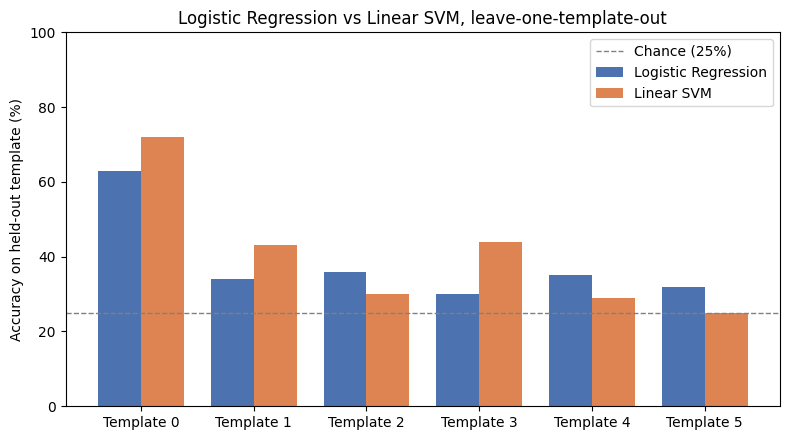

In [44]:
#  Step 20: Logistic Regression vs Linear SVM (same 6 leave-one-template-out folds) =====
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import binomtest

X_all = df_v2["text"].values
y_all = df_v2["category"].values
groups = df_v2["template_id"].values

def make_model(kind):
    tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
    clf = (LogisticRegression(max_iter=1000, random_state=SEED) if kind == "Logistic Regression"
           else LinearSVC(random_state=SEED))
    return Pipeline([("tfidf", tfidf), ("clf", clf)])

MODELS = ["Logistic Regression", "Linear SVM"]
gkf = GroupKFold(n_splits=6)
rows, timing = [], {m: {"fit": 0.0, "pred": 0.0, "n_pred": 0} for m in MODELS}

for tr, te in gkf.split(X_all, y_all, groups):
    held_out = int(np.unique(groups[te])[0])
    for m in MODELS:
        pipe = make_model(m)
        t0 = time.perf_counter(); pipe.fit(X_all[tr], y_all[tr]); t1 = time.perf_counter()
        pred = pipe.predict(X_all[te]); t2 = time.perf_counter()
        timing[m]["fit"] += t1 - t0; timing[m]["pred"] += t2 - t1; timing[m]["n_pred"] += len(te)
        rows.append({"Template": held_out, "Model": m,
                     "Accuracy": accuracy_score(y_all[te], pred),
                     "Macro F1": f1_score(y_all[te], pred, average="macro")})

svm_df = pd.DataFrame(rows)
acc = svm_df.pivot(index="Template", columns="Model", values="Accuracy")[MODELS]
f1  = svm_df.pivot(index="Template", columns="Model", values="Macro F1")[MODELS]

summary = pd.DataFrame({
    "Mean accuracy (%)": (acc.mean() * 100).round(2),
    "Mean macro F1": f1.mean().round(4),
    "Std of fold accuracy (pp)": (acc.std() * 100).round(2),
    "Train time / fold (ms)": [round(timing[m]["fit"] / 6 * 1000, 1) for m in MODELS],
    "Predict time / doc (µs)": [round(timing[m]["pred"] / timing[m]["n_pred"] * 1e6, 1) for m in MODELS],
})
print("Summary (same 6 held-out-template folds):")
display(summary)

per_t = (acc * 100).round(1)
per_t["Difference (SVM − LR, pp)"] = (per_t["Linear SVM"] - per_t["Logistic Regression"]).round(1)
per_t["Winner"] = np.where(per_t["Difference (SVM − LR, pp)"] > 0, "Linear SVM",
                   np.where(per_t["Difference (SVM − LR, pp)"] < 0, "Logistic Regression", "Tie"))
print("\nPer-template accuracy (%):")
display(per_t)

svm_wins = int((per_t["Winner"] == "Linear SVM").sum())
lr_wins  = int((per_t["Winner"] == "Logistic Regression").sum())
ties     = int((per_t["Winner"] == "Tie").sum())
n_dec = svm_wins + lr_wins
print(f"\nLinear SVM wins {svm_wins}, Logistic Regression wins {lr_wins}, ties {ties}.")
if n_dec > 0:
    p = binomtest(svm_wins, n_dec, 0.5).pvalue
    print(f"Exact two-sided sign test on the {n_dec} non-tied templates: p = {p:.4f} "
          f"(with 6 groups the smallest possible p is 0.031).")

# Chart
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(6); w = 0.38
ax.bar(x - w/2, per_t["Logistic Regression"], w, label="Logistic Regression", color="#4C72B0")
ax.bar(x + w/2, per_t["Linear SVM"], w, label="Linear SVM", color="#DD8452")
ax.axhline(25, color="gray", ls="--", lw=1, label="Chance (25%)")
ax.set_xticks(x); ax.set_xticklabels([f"Template {t}" for t in per_t.index])
ax.set_ylabel("Accuracy on held-out template (%)"); ax.set_ylim(0, 100)
ax.set_title("Logistic Regression vs Linear SVM, leave-one-template-out")
ax.legend(); plt.tight_layout(); plt.show()

### Results and Interpretation

Under identical leave-one-template-out folds, Linear SVM reached a mean accuracy of 40.50% (macro F1 0.3487), compared with 38.33% (macro F1 0.3437) for Logistic Regression. This 2.17 percentage-point difference in mean accuracy is small relative to the variation between folds. The standard deviation of fold accuracy was 12.27 pp for Logistic Regression and 17.28 pp for Linear SVM, so the SVM's results were also more uneven across templates.

The per-template table shows the two models trading wins. Linear SVM was better on templates 0, 1 and 3 (by 9, 9 and 14 points), and Logistic Regression was better on templates 2, 4 and 5 (by 6, 6 and 7 points). Each model won three templates, and the exact sign test gave p = 1.00, so there is no evidence that either classifier is consistently better. On template 5, Linear SVM scored 25.0%, which is exactly the chance level for four balanced classes.

Linear SVM trained faster in this run (about 176 ms per fold versus about 1,117 ms) and predicted slightly faster (about 214 µs versus 343 µs per document). These timings come from a shared Colab runtime on 600 short documents and are only indicative. Either model would classify a document in well under a millisecond, so speed is not a deciding factor at this scale.

These results come from six template groups on synthetic data. They show that this particular swap does not fix the generalization gap, not that Logistic Regression and Linear SVM are equivalent in general.

**Key Takeaway:** Changing the linear classifier did not meaningfully improve performance on unseen templates (38.33% vs 40.50%, with wins split 3–3). The main limitation is therefore the training data's template diversity, not the choice of model. Because Logistic Regression outputs class probabilities, which a confidence-threshold human-review workflow needs, and because its accuracy varied less across templates, it remains the preferred baseline for the architecture decision. Linear SVM is a reasonable alternative if probabilities are not needed.

In [45]:
!pip install rank_bm25 sentence-transformers

## Step 21: Retrieval Queries and Relevance Labels

### Objective

The classifier stage showed how well the system labels documents. This step starts the second stage: **retrieval**, meaning finding the right documents for a user's query. Before comparing retrieval methods, we need a query set with ground-truth relevance labels. The quality of this query set determines how meaningful the later comparison is.

**Query set (51 queries, five types):**
- **Keyword topic queries:** short queries such as "delay" or "damaged items"
- **Paraphrase topic queries:** descriptions that avoid the documents' own wording (e.g., "goods that arrived broken"), which test whether a method understands meaning and not only exact words
- **Category + topic queries:** e.g., "Invoice documents about delay". A document is relevant only if it matches both the category and the topic, so a shipping notice does not count as a correct answer for an invoice query.
- **Known-item queries (reference number / amount):** lookups where exactly one document is correct

**Relevance definitions:** Each query has a *strict* relevant set (the document's "Additional note" matches the topic) and a *combined* set (the note or a problem stated in the document body matches the topic). Both are evaluated in later steps.

**Metric choice:** Broad topic queries have 155–210 relevant documents out of 600, so Recall@3 is capped at about 1–2% and carries no information there. We therefore use Precision@3, Hit@3 and MRR for all query types, and report Recall@3 only for known-item queries, where there is exactly one relevant document. Results are reported by query type and are not pooled.

**Limitation:** The queries and labels are built from the same synthetic generator that produced the documents, so scores will be higher and cleaner than on real documents.

In [46]:
# ===== Step 21: Build retrieval queries and relevance labels =====
import re
import numpy as np
import pandas as pd

CATEGORIES = ["Invoice", "Purchase Order", "Shipping Notice", "Service Report"]
queries = []   # each: qid, qtype, query, rel_strict (set), rel_combined (set)

def add_query(qtype, text, strict_ids, combined_ids):
    queries.append({"qid": f"Q{len(queries)+1:02d}", "qtype": qtype, "query": text,
                    "rel_strict": set(strict_ids), "rel_combined": set(combined_ids)})

# --- A. Keyword topic queries (broad: 155-210 relevant docs each) ---
keyword_queries = [("delay", "delay"), ("delay", "delayed shipment"),
                   ("damage", "damaged items"), ("damage", "damage"),
                   ("payment", "payment issue"), ("payment", "outstanding payment")]
for topic, q in keyword_queries:
    add_query("Keyword topic", q, relevant_ids(topic, "strict"), relevant_ids(topic, "combined"))

# --- B. Paraphrase queries: deliberately avoid the words the documents use ---
# >>> REVIEW THESE: edit, delete or add your own. Avoid words such as delay, damaged,
# >>> defects, payment, outstanding, billing, financial, discrepancy.
paraphrase_queries = [
    ("delay",   "shipments running behind schedule"),
    ("delay",   "goods that did not arrive when promised"),
    ("delay",   "deliveries taking longer than expected"),
    ("damage",  "goods that arrived broken"),
    ("damage",  "items in poor physical shape"),
    ("damage",  "products harmed in transit"),
    ("payment", "money owed that has not been settled"),
    ("payment", "disputes about what a customer was charged"),
    ("payment", "unpaid balances awaiting approval"),
]
for topic, q in paraphrase_queries:
    add_query("Paraphrase topic", q, relevant_ids(topic, "strict"), relevant_ids(topic, "combined"))

# --- C. Category + topic queries: relevant = category AND topic (intersection) ---
TOPIC_WORDS = {"delay": "delay", "damage": "damage", "payment": "payment problem"}
for cat in CATEGORIES:
    cat_ids = set(df_v2.loc[df_v2["category"] == cat, "document_id"])
    for topic, word in TOPIC_WORDS.items():
        add_query("Category + topic", f"{cat} documents about {word}",
                  relevant_ids(topic, "strict") & cat_ids,
                  relevant_ids(topic, "combined") & cat_ids)

# --- D. Known-item queries: exactly one correct document ---
rng_df = df_v2.copy()
rng_df["ref"] = rng_df["text"].str.extract(r"(REF-\d+)")[0]
rng_df["amount"] = rng_df["text"].str.extract(r"\$(\d+\.?\d*)")[0]

# D1: lookup by reference number (3 per category)
for cat in CATEGORIES:
    pool = rng_df[(rng_df["category"] == cat) & rng_df["ref"].notna()]
    for _, r in pool.sample(3, random_state=SEED).iterrows():
        ids = set(rng_df.loc[rng_df["ref"] == r["ref"], "document_id"])
        add_query("Known-item (reference)", f"{cat} with reference {r['ref']}", ids, ids)

# D2: lookup by dollar amount (6 each for the two categories that state amounts)
for cat in ["Invoice", "Purchase Order"]:
    pool = rng_df[(rng_df["category"] == cat) & rng_df["amount"].notna()]
    for _, r in pool.sample(6, random_state=SEED).iterrows():
        ids = set(rng_df.loc[rng_df["amount"] == r["amount"], "document_id"])
        add_query("Known-item (amount)", f"{cat} for the amount ${r['amount']}", ids, ids)

queries_df = pd.DataFrame(queries)
queries_df["n_strict"] = queries_df["rel_strict"].apply(len)
queries_df["n_combined"] = queries_df["rel_combined"].apply(len)

# --- Sanity checks ---
assert (queries_df["n_strict"] > 0).all() and (queries_df["n_combined"] > 0).all(), "empty relevant set"
ki = queries_df["qtype"].str.startswith("Known-item")
assert (queries_df.loc[ki, "n_combined"] == 1).all(), "known-item query should have exactly 1 relevant doc"
assert queries_df["qid"].is_unique

print(f"Total queries: {len(queries_df)}")
summary_q = (queries_df.groupby("qtype", sort=False)
             .agg(n_queries=("qid", "count"),
                  min_relevant=("n_combined", "min"),
                  median_relevant=("n_combined", "median"),
                  max_relevant=("n_combined", "max")))
display(summary_q)

print("\nExample query from each type:")
display(queries_df.groupby("qtype", sort=False).head(1)[["qid", "qtype", "query", "n_strict", "n_combined"]])

print("\nCategory + topic relevant-set sizes (combined):")
cp = queries_df[queries_df["qtype"] == "Category + topic"][["query", "n_strict", "n_combined"]]
display(cp.reset_index(drop=True))

print("\nReminder: Recall@3 is only reported for known-item queries (1 relevant doc). "
      "For all other types use Precision@3, Hit@3 and MRR, because the relevant sets are far larger than 3.")

Total queries: 51


,n_queries,min_relevant,median_relevant,max_relevant
qtype,,,,
Keyword topic,6,173,178.0,210
Paraphrase topic,9,173,178.0,210
Category + topic,12,35,43.0,79
Known-item (reference),12,1,1.0,1
Known-item (amount),12,1,1.0,1



Example query from each type:


,qid,qtype,query,n_strict,n_combined
0,Q01,Keyword topic,delay,155,173
6,Q07,Paraphrase topic,shipments running behind schedule,155,173
15,Q16,Category + topic,Invoice documents about delay,35,35
27,Q28,Known-item (reference),Invoice with reference REF-61559,1,1
39,Q40,Known-item (amount),Invoice for the amount $9813.38,1,1



Category + topic relevant-set sizes (combined):


,query,n_strict,n_combined
0,Invoice documents about delay,35,35
1,Invoice documents about damage,42,42
2,Invoice documents about payment problem,41,79
3,Purchase Order documents about delay,38,38
4,Purchase Order documents about damage,41,41
5,Purchase Order documents about payment problem,42,42
6,Shipping Notice documents about delay,36,54
7,Shipping Notice documents about damage,38,38
8,Shipping Notice documents about payment problem,44,44
9,Service Report documents about delay,46,46



Reminder: Recall@3 is only reported for known-item queries (1 relevant doc). For all other types use Precision@3, Hit@3 and MRR, because the relevant sets are far larger than 3.


### Results and Interpretation

The query set contains 51 queries across five types: 6 keyword topic queries, 9 paraphrase topic queries, 12 category-plus-topic queries, 12 known-item queries by reference number and 12 known-item queries by dollar amount. All relevance sets are non-empty, and every known-item query has exactly one relevant document, as intended.

The relevant-set sizes differ sharply by type. Broad topic queries (keyword and paraphrase) have between 173 and 210 relevant documents out of 600 under the combined definition (155 to 172 under the strict one). That is about 29% to 35% of the corpus, so a system that returned random documents would already find a relevant one often. Category-plus-topic queries are narrower, with 35 to 79 relevant documents. Known-item queries have a single correct answer.

This changes how we measure. For broad queries Recall@3 would be capped at roughly 1–2% even for a perfect system, so we use Precision@3, Hit@3 and MRR for all query types and report Recall@3 only for the known-item queries.

**Key Takeaway:** The three methods should be compared separately for each query type, and the differences between methods are likely to appear on the hard types (paraphrase and known-item) and not on the broad keyword queries, where almost any method will succeed. All labels come from the synthetic generator, so absolute scores will be more favorable than on real documents.

## Step 22: Building Three Retrieval Methods

### Objective

This step builds three ways to search the 600 documents so they can be compared on the same queries in Step 23.

- **TF-IDF cosine similarity:** represents each document and query as a weighted word vector and ranks by similarity. This is the same representation used for classification.
- **BM25:** a keyword-ranking function that adds term-frequency saturation and document-length normalization to TF-IDF-style weighting. It is a standard baseline for search.
- **Sentence embeddings (all-MiniLM-L6-v2):** a pretrained model that maps text to dense vectors that capture meaning, so a query can match a document even without shared words.

**Design choices that keep the comparison fair:**
- All three methods search the same 600 documents and expose the same function, `rank_docs(method, query, k)`.
- Tied scores are broken with a fixed random order, not document order. Documents are stored sorted by category, so document order would silently favor Invoices.
- If a lexical method (TF-IDF or BM25) finds none of the query's words in any document, it returns no results, which counts as a failure, and does not fall back to an arbitrary ordering.

The cell also prints one-off index build time and the top-3 results for one example query of each type as a sanity check. Accuracy is evaluated in Step 23.

In [47]:
# ===== Step 22: Build three retrievers over the same 600 documents =====
import re, time
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

doc_ids   = df_v2["document_id"].tolist()
doc_texts = df_v2["text"].tolist()
doc_cats  = df_v2["category"].tolist()
N_DOCS = len(doc_ids)

def tokenize(s):
    return re.findall(r"[a-z0-9]+", s.lower())

build_times = {}

# --- 1. TF-IDF cosine similarity ---
t0 = time.perf_counter()
tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
tfidf_docs = tfidf_vec.fit_transform(doc_texts)            # rows are L2-normalized
build_times["TF-IDF"] = time.perf_counter() - t0

def score_tfidf(query):
    q = tfidf_vec.transform([query])
    return (tfidf_docs @ q.T).toarray().ravel()            # cosine similarity

# --- 2. BM25 (Okapi) ---
t0 = time.perf_counter()
bm25 = BM25Okapi([tokenize(t) for t in doc_texts])
build_times["BM25"] = time.perf_counter() - t0

def score_bm25(query):
    return np.asarray(bm25.get_scores(tokenize(query)), dtype=float)

# --- 3. Sentence embeddings (all-MiniLM-L6-v2) ---
t0 = time.perf_counter()
emb_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
doc_emb = emb_model.encode(doc_texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
build_times["Embeddings"] = time.perf_counter() - t0

def score_embeddings(query):
    q = emb_model.encode([query], normalize_embeddings=True, show_progress_bar=False)[0]
    return doc_emb @ q                                      # cosine similarity (vectors are normalized)

RETRIEVERS = {"TF-IDF": score_tfidf, "BM25": score_bm25, "Embeddings": score_embeddings}

# Fixed random tie-break order, so tied scores are not resolved by document order
# (documents are stored sorted by category, which would silently favor Invoices).
TIE_RANK = np.random.default_rng(SEED).permutation(N_DOCS)

def rank_docs(method, query, k=None):
    """Return (document ids best-first, scores). If a method has no signal at all
    (every score is 0, e.g. no query word occurs in any document) it returns NO results."""
    scores = RETRIEVERS[method](query)
    if method in ("TF-IDF", "BM25") and np.max(scores) <= 0:
        return [], np.array([])
    order = np.lexsort((TIE_RANK, -scores))      # primary: score (desc); secondary: fixed random rank
    if k is not None:
        order = order[:k]
    return [doc_ids[i] for i in order], scores[order]

print("Index build time (one-off, seconds):")
display(pd.Series(build_times, name="seconds").round(3).to_frame())

# --- Sanity check: top-3 for one example query per type, with category and relevance ---
cat_lookup = dict(zip(doc_ids, doc_cats))
examples = queries_df.groupby("qtype", sort=False).head(1)
for _, row in examples.iterrows():
    print(f"\n[{row['qid']}] ({row['qtype']}) {row['query']}   -- relevant docs: {row['n_combined']}")
    for m in RETRIEVERS:
        top_ids, top_scores = rank_docs(m, row["query"], k=3)
        shown = [f"{d}({cat_lookup[d]}, {'REL' if d in row['rel_combined'] else 'not'}, {s:.2f})"
                 for d, s in zip(top_ids, top_scores)]
        print(f"  {m:11s}: " + (" | ".join(shown) if shown else "NO RESULTS (no query word matched any document)"))

# --- Zero-score warning: how often does a method return no signal at all? ---
zero = {m: int(sum(float(np.max(RETRIEVERS[m](q))) <= 0 for q in queries_df["query"])) for m in ["TF-IDF", "BM25"]}
print(f"\nQueries where the best score is 0 (no query word found in any document): {zero}")
print("These queries return no results and count as failures (0 precision, 0 reciprocal rank) in Step 23.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Index build time (one-off, seconds):


,seconds
TF-IDF,0.062
BM25,0.022
Embeddings,20.657



[Q01] (Keyword topic) delay   -- relevant docs: 173
  TF-IDF     : NEW-0449(Shipping Notice, REL, 0.16) | NEW-0434(Shipping Notice, REL, 0.16) | NEW-0507(Service Report, REL, 0.16)
  BM25       : NEW-0499(Service Report, REL, 2.54) | NEW-0492(Service Report, REL, 2.54) | NEW-0292(Purchase Order, REL, 2.48)
  Embeddings : NEW-0475(Service Report, REL, 0.47) | NEW-0449(Shipping Notice, REL, 0.45) | NEW-0361(Shipping Notice, REL, 0.44)

[Q07] (Paraphrase topic) shipments running behind schedule   -- relevant docs: 173
  TF-IDF     : NO RESULTS (no query word matched any document)
  BM25       : NO RESULTS (no query word matched any document)
  Embeddings : NEW-0233(Purchase Order, REL, 0.56) | NEW-0236(Purchase Order, REL, 0.56) | NEW-0243(Purchase Order, REL, 0.56)

[Q16] (Category + topic) Invoice documents about delay   -- relevant docs: 35
  TF-IDF     : NEW-0091(Invoice, REL, 0.21) | NEW-0095(Invoice, REL, 0.19) | NEW-0086(Invoice, not, 0.15)
  BM25       : NEW-0091(Invoice, REL, 5.

### Results and Interpretation

All three retrievers built successfully over the same 600 documents. TF-IDF and BM25 index in well under a tenth of a second (0.062 s and 0.022 s). The embedding index took 20.7 s, but that figure includes loading and downloading the pretrained model, so it is a one-off setup cost and not a per-query cost. Per-query latency is measured separately in Step 23.

The example queries already show different behavior by query type. These are single examples and not performance estimates:

- **Broad keyword query ("delay"):** all three methods returned three relevant documents. With 173 relevant documents out of 600, this type is easy and is unlikely to separate the methods.
- **Paraphrase query ("shipments running behind schedule"):** TF-IDF and BM25 returned no results, because none of the query's words appear in any document. Embeddings returned three relevant documents. Two of the 51 queries produced no lexical match at all.
- **Category + topic query ("Invoice documents about delay"):** TF-IDF and BM25 each returned two relevant Invoice documents in the top three. Embeddings returned documents about delay from other categories (Service Report, Shipping Notice, Purchase Order), so none of the three was relevant under the intersection definition. The embedding model captured the topic but ignored the requested category.
- **Known-item queries (reference number and amount):** TF-IDF and BM25 ranked the correct document first in both examples. Embeddings did not place it in the top three in either, which is consistent with embeddings not representing exact numbers well.

**Key Takeaway:** The methods appear to have complementary strengths: lexical methods are precise when exact words or numbers are available and fail when wording changes, while embeddings handle paraphrase but are weaker on exact identifiers and on category constraints. Whether this pattern holds across all 51 queries, and how large the differences are, is tested in Step 23.

## Step 23: Retrieval Evaluation

### Objective

This step measures how well TF-IDF, BM25 and sentence embeddings retrieve the correct documents for each of the 51 queries from Step 21.

**Metrics (top 3 results unless noted):**
- **Precision@3:** the fraction of the top three results that are relevant
- **Hit@3:** whether at least one of the top three is relevant
- **MRR (mean reciprocal rank):** the average of 1 ÷ (rank of the first relevant result), computed over the full ranking
- **Recall@3:** reported only for known-item queries, where there is exactly one relevant document, so it equals Hit@3
- **Latency:** median time to answer one query, including query encoding

**Rules:**
- Results are reported separately for each query type and are not pooled across types.
- Every metric is computed under both the *strict* and *combined* relevance definitions.
- For TF-IDF and BM25, a document with a score of 0 is treated as not retrieved. A query with no matching words returns nothing and scores 0 on every metric.
- Per-query results are stored so that Step 24 can compute bootstrap confidence intervals and paired comparisons.

**Limitation:** with 51 queries, 12 per known-item type and 6–12 per other type, differences between methods are estimates with real uncertainty, which Step 24 quantifies.

=== COMBINED relevance (note OR body topic) ===


P@3  Hit@3    MRR
qtype                  method                         
Keyword topic          TF-IDF      0.833  0.833  0.833
                       BM25        0.833  0.833  0.833
                       Embeddings  0.944  1.000  0.917
Paraphrase topic       TF-IDF      0.444  0.444  0.493
                       BM25        0.444  0.444  0.477
                       Embeddings  0.815  1.000  0.815
Category + topic       TF-IDF      0.167  0.250  0.236
                       BM25        0.139  0.167  0.217
                       Embeddings  0.528  0.750  0.670
Known-item (reference) TF-IDF      0.333  1.000  1.000
                       BM25        0.333  1.000  1.000
                       Embeddings  0.056  0.167  0.169
Known-item (amount)    TF-IDF      0.333  1.000  1.000
                       BM25        0.333  1.000  1.000
                       Embeddings  0.083  0.250  0.246


=== STRICT relevance (note topic only) ===


P@3  Hit@3    MRR
qtype                  method                         
Keyword topic          TF-IDF      0.611  0.667  0.596
                       BM25        0.444  0.500  0.545
                       Embeddings  0.778  1.000  0.917
Paraphrase topic       TF-IDF      0.370  0.444  0.437
                       BM25        0.333  0.333  0.380
                       Embeddings  0.704  1.000  0.759
Category + topic       TF-IDF      0.167  0.250  0.236
                       BM25        0.139  0.167  0.217
                       Embeddings  0.472  0.750  0.615
Known-item (reference) TF-IDF      0.333  1.000  1.000
                       BM25        0.333  1.000  1.000
                       Embeddings  0.056  0.167  0.169
Known-item (amount)    TF-IDF      0.333  1.000  1.000
                       BM25        0.333  1.000  1.000
                       Embeddings  0.083  0.250  0.246


Recall@3 on known-item queries (equals Hit@3 because there is one relevant document):


method,TF-IDF,BM25,Embeddings
qtype,,,
Known-item (amount),1.0,1.0,0.250
Known-item (reference),1.0,1.0,0.167



Queries with NO results (count per query type):


method,TF-IDF,BM25,Embeddings
qtype,,,
Keyword topic,1,1,0
Paraphrase topic,1,1,0
Category + topic,0,0,0
Known-item (reference),0,0,0
Known-item (amount),0,0,0



Query latency (includes query encoding for Embeddings; CPU):


,Median latency (ms),95th pct latency (ms)
method,,
TF-IDF,2.29,7.24
BM25,1.93,6.27
Embeddings,43.32,107.11


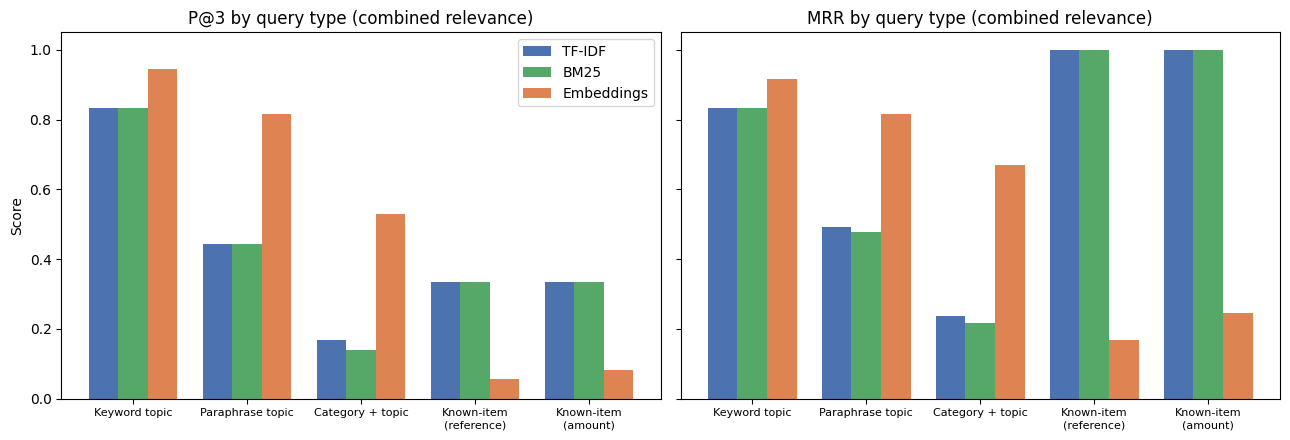

In [48]:
# ===== Step 23: Retrieval evaluation =====
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

K = 3
METHODS = ["TF-IDF", "BM25", "Embeddings"]
LEXICAL = {"TF-IDF", "BM25"}

def retrieve(method, query):
    """Full ranking for one query. For lexical methods, documents with score 0 are 'not retrieved'."""
    ids, scores = rank_docs(method, query, k=None)
    if method in LEXICAL:
        keep = [i for i, s in enumerate(scores) if s > 0]
        ids = [ids[i] for i in keep]
    return ids

records = []
for _, q in queries_df.iterrows():
    for m in METHODS:
        ranked = retrieve(m, q["query"])
        top = ranked[:K]
        for definition, rel in [("combined", q["rel_combined"]), ("strict", q["rel_strict"])]:
            hits_top = sum(d in rel for d in top)
            first_rank = next((r for r, d in enumerate(ranked, start=1) if d in rel), None)
            records.append({
                "qid": q["qid"], "qtype": q["qtype"], "method": m, "definition": definition,
                "P@3": hits_top / K,
                "Hit@3": float(hits_top > 0),
                "RR": (1.0 / first_rank) if first_rank else 0.0,
                "n_returned": len(ranked),
            })

retr = pd.DataFrame(records)
QTYPE_ORDER = list(queries_df["qtype"].drop_duplicates())

def summarize(definition):
    t = (retr[retr["definition"] == definition]
         .groupby(["qtype", "method"])[["P@3", "Hit@3", "RR"]].mean()
         .rename(columns={"RR": "MRR"}).round(3))
    t = t.reindex(pd.MultiIndex.from_product([QTYPE_ORDER, METHODS], names=["qtype", "method"]))
    return t

print("=== COMBINED relevance (note OR body topic) ===")
display(summarize("combined"))
print("\n=== STRICT relevance (note topic only) ===")
display(summarize("strict"))

# Recall@3 for known-item queries (exactly 1 relevant doc, so Recall@3 = Hit@3)
ki = retr[(retr["definition"] == "combined") & retr["qtype"].str.startswith("Known-item")]
print("\nRecall@3 on known-item queries (equals Hit@3 because there is one relevant document):")
display(ki.groupby(["qtype", "method"])["Hit@3"].mean().rename("Recall@3").round(3).unstack("method")[METHODS])

# How often did a method return nothing at all?
zero = (retr[retr["definition"] == "combined"].assign(no_result=lambda d: d["n_returned"] == 0)
        .groupby(["qtype", "method"])["no_result"].sum().unstack("method")[METHODS].reindex(QTYPE_ORDER))
print("\nQueries with NO results (count per query type):")
display(zero)

# Latency: median of 5 repeats per query, then summarized across the 51 queries
lat_rows = []
for _, q in queries_df.iterrows():
    for m in METHODS:
        times = []
        for _ in range(5):
            t0 = time.perf_counter(); rank_docs(m, q["query"], k=K); times.append(time.perf_counter() - t0)
        lat_rows.append({"method": m, "ms": float(np.median(times)) * 1000})
lat = pd.DataFrame(lat_rows).groupby("method")["ms"].agg(
    median="median", p95=lambda s: np.percentile(s, 95)).round(2).reindex(METHODS)
lat.columns = ["Median latency (ms)", "95th pct latency (ms)"]
print("\nQuery latency (includes query encoding for Embeddings; CPU):")
display(lat)

# Chart: P@3 and MRR by query type (combined relevance)
comb = summarize("combined")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {"TF-IDF": "#4C72B0", "BM25": "#55A868", "Embeddings": "#DD8452"}
x = np.arange(len(QTYPE_ORDER)); w = 0.26
for ax, metric in zip(axes, ["P@3", "MRR"]):
    for j, m in enumerate(METHODS):
        vals = [comb.loc[(qt, m), metric] for qt in QTYPE_ORDER]
        ax.bar(x + (j - 1) * w, vals, w, label=m, color=colors[m])
    ax.set_xticks(x); ax.set_xticklabels([q.replace(" (", "\n(") for q in QTYPE_ORDER], fontsize=8)
    ax.set_title(f"{metric} by query type (combined relevance)"); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Score"); axes[0].legend()
plt.tight_layout(); plt.show()

### Results and Interpretation

No single method was best across all query types. Results below use the combined relevance definition unless stated; the strict definition gives the same ordering of methods on every query type.

**Broad topic queries.** On keyword queries, sentence embeddings scored Precision@3 of 0.944 and MRR of 0.917, compared with 0.833 and 0.833 for both TF-IDF and BM25. The lexical methods' lower scores come from a single query (the word "damage" never appears in the corpus, which uses "damaged") that returned no results. On paraphrase queries the gap is large: embeddings reached Precision@3 of 0.815 and Hit@3 of 1.000, while TF-IDF and BM25 reached 0.444 for both, because queries written without the documents' vocabulary often match no words at all. One paraphrase query returned no lexical results.

**Category + topic queries.** Embeddings were clearly better (Precision@3 0.528, MRR 0.670) than TF-IDF (0.167, 0.236) and BM25 (0.139, 0.217). A likely explanation is that the category names never appear in the document text, so lexical methods cannot use the category part of the query and only match the topic word, while embeddings can infer the category from the content.

**Known-item queries.** The pattern reverses. TF-IDF and BM25 ranked the correct document first for all 12 reference queries and all 12 amount queries (Hit@3 = Recall@3 = 1.000, MRR = 1.000). Embeddings found the correct document in the top three for only 0.167 of reference queries and 0.250 of amount queries (MRR 0.169 and 0.246). The Precision@3 of 0.333 for the lexical methods on these queries is the maximum possible, since only one document is relevant.

**Latency.** Median query latency on this CPU runtime was 2.29 ms for TF-IDF and 1.93 ms for BM25, against 43.32 ms for embeddings (95th percentile 7.24, 6.27 and 107.11 ms). Embeddings are roughly 20 times slower, but all three are fast enough for interactive use at this corpus size.

**Limitations.** Each query type has only 6 to 12 queries, so these are point estimates with substantial uncertainty (quantified in the next step). The paraphrase queries were written to avoid the documents' vocabulary and the known-item queries rely on exact identifiers, so each type is designed to favor one family of methods. The results show complementary strengths and do not prove that one method is better overall. All labels come from the synthetic generator.

**Key Takeaway:** Lexical methods (BM25, TF-IDF) are the right tool for exact identifiers such as reference numbers and amounts, while embeddings are the right tool for meaning-based and category-aware queries. Neither alone covers both needs, which motivates testing a hybrid that combines them.

## Step 24: Hybrid Retrieval (BM25 + Embeddings)

### Objective

Step 23 showed complementary strengths: BM25 and TF-IDF were best at exact identifiers (reference numbers and amounts), while embeddings were best at paraphrase and category-aware queries. This step tests whether combining the two methods recovers the strengths of both.

**Method: Reciprocal Rank Fusion (RRF).** For each query, BM25 and the embedding model each produce a ranked list. A document's fused score is the sum, over the two lists, of 1 ÷ (60 + its rank in that list). Documents ranked highly by both methods rise to the top. The constant 60 is the standard default from the RRF literature and was **not tuned** on our queries, so the comparison is not inflated by tuning on the test set. A document that BM25 did not retrieve at all (score 0) receives no BM25 contribution.

**Evaluation:** identical to Step 23 (Precision@3, Hit@3, MRR under both relevance definitions, by query type), plus a per-query check of where the hybrid does worse than the best single method.

**What this step can show:** whether equal-weight fusion helps, hurts, or is neutral on each query type. A hybrid is not guaranteed to win: if one method is strong and the other is weak on a query type, fusing them can dilute the strong signal.

=== COMBINED relevance: all four methods ===


P@3  Hit@3    MRR
qtype                  method                                         
Keyword topic          TF-IDF                      0.833  0.833  0.833
                       BM25                        0.833  0.833  0.833
                       Embeddings                  0.944  1.000  0.917
                       Hybrid (BM25 + Embeddings)  1.000  1.000  1.000
Paraphrase topic       TF-IDF                      0.444  0.444  0.493
                       BM25                        0.444  0.444  0.477
                       Embeddings                  0.815  1.000  0.815
                       Hybrid (BM25 + Embeddings)  0.630  0.889  0.769
Category + topic       TF-IDF                      0.167  0.250  0.236
                       BM25                        0.139  0.167  0.217
                       Embeddings                  0.528  0.750  0.670
                       Hybrid (BM25 + Embeddings)  0.389  0.583  0.544
Known-item (reference) TF-IDF                      0.333  1.000  1.000
                       BM25                        0.333  1.000  1.000
                       Embeddings                  0.056  0.167  0.169
                       Hybrid (BM25 + Embeddings)  0.250  0.750  0.717
Known-item (amount)    TF-IDF                      0.333  1.000  1.000
                       BM25                        0.333  1.000  1.000
                       Embeddings                  0.083  0.250  0.246
                       Hybrid (BM25 + Embeddings)  0.222  0.667  0.625


=== STRICT relevance: all four methods ===


P@3  Hit@3    MRR
qtype                  method                                         
Keyword topic          TF-IDF                      0.611  0.667  0.596
                       BM25                        0.444  0.500  0.545
                       Embeddings                  0.778  1.000  0.917
                       Hybrid (BM25 + Embeddings)  0.778  1.000  0.806
Paraphrase topic       TF-IDF                      0.370  0.444  0.437
                       BM25                        0.333  0.333  0.380
                       Embeddings                  0.704  1.000  0.759
                       Hybrid (BM25 + Embeddings)  0.556  0.889  0.713
Category + topic       TF-IDF                      0.167  0.250  0.236
                       BM25                        0.139  0.167  0.217
                       Embeddings                  0.472  0.750  0.615
                       Hybrid (BM25 + Embeddings)  0.389  0.583  0.544
Known-item (reference) TF-IDF                      0.333  1.000  1.000
                       BM25                        0.333  1.000  1.000
                       Embeddings                  0.056  0.167  0.169
                       Hybrid (BM25 + Embeddings)  0.250  0.750  0.717
Known-item (amount)    TF-IDF                      0.333  1.000  1.000
                       BM25                        0.333  1.000  1.000
                       Embeddings                  0.083  0.250  0.246
                       Hybrid (BM25 + Embeddings)  0.222  0.667  0.625


MRR by query type (combined relevance):


method,TF-IDF,BM25,Embeddings,Hybrid (BM25 + Embeddings)
qtype,,,,
Keyword topic,0.833,0.833,0.917,1.000
Paraphrase topic,0.493,0.477,0.815,0.769
Category + topic,0.236,0.217,0.670,0.544
Known-item (reference),1.000,1.000,0.169,0.717
Known-item (amount),1.000,1.000,0.246,0.625



Hybrid latency: median 38.32 ms, 95th percentile 102.78 ms

Queries where the hybrid's reciprocal rank is below the best single method: 19 of 51


,,query,Hybrid (BM25 + Embeddings),best_single,hybrid_gap
qid,qtype,,,,
Q09,Paraphrase topic,deliveries taking longer than expected,0.333333,1.000,-0.667
Q10,Paraphrase topic,goods that arrived broken,0.500000,1.000,-0.500
Q13,Paraphrase topic,money owed that has not been settled,0.083333,0.500,-0.417
Q16,Category + topic,Invoice documents about delay,0.250000,1.000,-0.750
Q20,Category + topic,Purchase Order documents about damage,0.035714,0.125,-0.089
Q21,Category + topic,Purchase Order documents about payment problem,0.142857,1.000,-0.857
Q23,Category + topic,Shipping Notice documents about damage,0.058824,1.000,-0.941
Q26,Category + topic,Service Report documents about damage,0.500000,1.000,-0.500
Q27,Category + topic,Service Report documents about payment problem,0.500000,1.000,-0.500


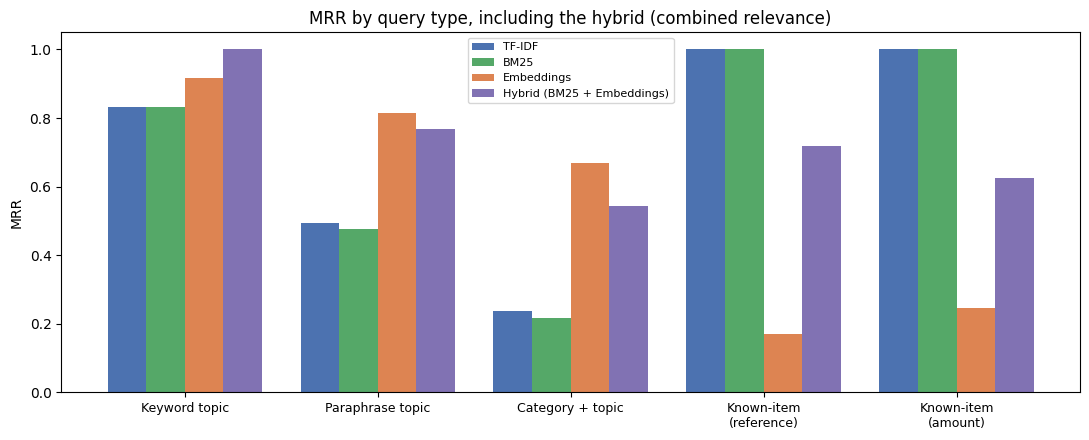

In [49]:
# ===== Step 24: Hybrid retrieval (BM25 + Embeddings, fused with Reciprocal Rank Fusion) =====
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RRF_K = 60            # standard default from the RRF literature; NOT tuned on our queries
HYBRID = "Hybrid (BM25 + Embeddings)"
doc_index = {d: i for i, d in enumerate(doc_ids)}

def hybrid_ranking(query):
    """Reciprocal Rank Fusion: each document gets sum over methods of 1 / (RRF_K + rank).
    A document a method did not retrieve (BM25 score 0) simply gets no contribution from it."""
    fused = {}
    for m in ["BM25", "Embeddings"]:
        for rank, d in enumerate(retrieve(m, query), start=1):
            fused[d] = fused.get(d, 0.0) + 1.0 / (RRF_K + rank)
    # sort by fused score (desc); ties broken by the same fixed random order as Step 22
    return sorted(fused, key=lambda d: (-fused[d], TIE_RANK[doc_index[d]]))

# --- Evaluate with exactly the same metrics as Step 23 ---
hyb_records = []
for _, q in queries_df.iterrows():
    ranked = hybrid_ranking(q["query"]); top = ranked[:K]
    for definition, rel in [("combined", q["rel_combined"]), ("strict", q["rel_strict"])]:
        hits_top = sum(d in rel for d in top)
        first_rank = next((r for r, d in enumerate(ranked, start=1) if d in rel), None)
        hyb_records.append({"qid": q["qid"], "qtype": q["qtype"], "method": HYBRID, "definition": definition,
                            "P@3": hits_top / K, "Hit@3": float(hits_top > 0),
                            "RR": (1.0 / first_rank) if first_rank else 0.0, "n_returned": len(ranked)})

retr = pd.concat([retr[retr["method"] != HYBRID], pd.DataFrame(hyb_records)], ignore_index=True)
ALL_METHODS = ["TF-IDF", "BM25", "Embeddings", HYBRID]

def summarize4(definition):
    t = (retr[retr["definition"] == definition]
         .groupby(["qtype", "method"])[["P@3", "Hit@3", "RR"]].mean()
         .rename(columns={"RR": "MRR"}).round(3))
    return t.reindex(pd.MultiIndex.from_product([QTYPE_ORDER, ALL_METHODS], names=["qtype", "method"]))

print("=== COMBINED relevance: all four methods ===")
display(summarize4("combined"))
print("\n=== STRICT relevance: all four methods ===")
display(summarize4("strict"))

# --- Compact view: MRR by query type (combined), one row per type ---
mrr_view = (summarize4("combined")["MRR"].unstack("method")[ALL_METHODS].reindex(QTYPE_ORDER))
print("\nMRR by query type (combined relevance):")
display(mrr_view)

# --- Latency of the hybrid (runs BM25 + embeddings + fusion) ---
times = []
for _, q in queries_df.iterrows():
    ts = []
    for _ in range(5):
        t0 = time.perf_counter(); hybrid_ranking(q["query"]); ts.append(time.perf_counter() - t0)
    times.append(float(np.median(ts)) * 1000)
print(f"\nHybrid latency: median {np.median(times):.2f} ms, 95th percentile {np.percentile(times, 95):.2f} ms")

# --- Where does the hybrid lose to the best single method? (per-query, combined MRR) ---
pq = (retr[retr["definition"] == "combined"].pivot_table(index=["qid", "qtype"], columns="method", values="RR")[ALL_METHODS])
pq["best_single"] = pq[METHODS].max(axis=1)
pq["hybrid_gap"] = (pq[HYBRID] - pq["best_single"]).round(3)
worse = pq[pq["hybrid_gap"] < 0]
print(f"\nQueries where the hybrid's reciprocal rank is below the best single method: {len(worse)} of {len(pq)}")
if len(worse):
    display(worse.join(queries_df.set_index("qid")["query"], on="qid")[["query", HYBRID, "best_single", "hybrid_gap"]].head(15))

# --- Chart: MRR by query type for all four methods ---
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = {"TF-IDF": "#4C72B0", "BM25": "#55A868", "Embeddings": "#DD8452", HYBRID: "#8172B3"}
x = np.arange(len(QTYPE_ORDER)); w = 0.2
for j, m in enumerate(ALL_METHODS):
    ax.bar(x + (j - 1.5) * w, [mrr_view.loc[qt, m] for qt in QTYPE_ORDER], w, label=m, color=colors[m])
ax.set_xticks(x); ax.set_xticklabels([q.replace(" (", "\n(") for q in QTYPE_ORDER], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel("MRR"); ax.set_title("MRR by query type, including the hybrid (combined relevance)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Results and Interpretation

Equal-weight fusion of BM25 and embeddings produced a **compromise, not a winner**. Under the combined relevance definition, MRR was:

| Query type | TF-IDF | BM25 | Embeddings | Hybrid |
|---|---|---|---|---|
| Keyword topic | 0.833 | 0.833 | 0.917 | **1.000** |
| Paraphrase topic | 0.493 | 0.477 | **0.815** | 0.769 |
| Category + topic | 0.236 | 0.217 | **0.670** | 0.544 |
| Known-item (reference) | **1.000** | **1.000** | 0.169 | 0.717 |
| Known-item (amount) | **1.000** | **1.000** | 0.246 | 0.625 |

The hybrid recovered much of what embeddings lack on exact identifiers (MRR 0.717 and 0.625 versus 0.169 and 0.246) while keeping most of the embeddings' strength on paraphrase and category queries (0.769 and 0.544 versus 0.815 and 0.670). It did not match the best single method on any type except keyword queries, and under the strict relevance definition it did not beat embeddings there either (MRR 0.806 versus 0.917), so the keyword result depends on the relevance definition. The hybrid scored below the best single method on 19 of 51 queries.

Its main strength is robustness. Its lowest MRR across the five query types is 0.544, while the lowest for TF-IDF, BM25 and embeddings is 0.236, 0.217 and 0.169. No query type breaks it, but it is also never the clear best. Latency is about the same as embeddings alone (median 38.32 ms, 95th percentile 102.78 ms), since encoding the query dominates the cost.

The likely reason it falls short on known-item queries is that RRF gives the two rankers equal weight: a document that BM25 ranks first but embeddings rank poorly is outscored by documents that both methods rank moderately well.

**Limitations.** Each query type has only 6 to 12 queries, so these differences are estimates with real uncertainty, quantified in the next step. The fusion constant (60) was not tuned, which avoids overfitting to this query set but may leave performance on the table.

**Key Takeaway:** A fixed equal-weight hybrid is a safe, balanced default but not the best choice for any query type except possibly broad keyword queries. The results suggest that routing queries by their form (identifier-like queries to BM25, meaning-based queries to embeddings) could outperform a single fused ranking, which is tested next.

## Step 25: Query Router, Confidence Intervals, and Paired Comparisons

### Objective

Step 24 showed that an equal-weight hybrid is a balanced compromise but is not the best method on most query types. This step tests a simple alternative and then asks how much the differences between all methods can be trusted.

**1. Query router.** A rule that inspects the query: if it contains an identifier (a `REF-` number or a `$` amount), search with BM25; otherwise use sentence embeddings. **Two cautions:** every known-item query in our set contains such an identifier, so the router equals BM25 on those queries by construction and its score there is not an independent finding. The choice of embeddings for all other queries was also informed by the same 51 evaluation queries, so the router's overall score is somewhat optimistic.

**2. Bootstrap confidence intervals.** For each query type and method, we resample the queries with replacement 10,000 times and report the 2.5th–97.5th percentile of the resulting MRR. This shows how much each score could change with a different set of queries.

**3. Paired comparisons.** For selected pairs of methods we compute, on the same queries, the mean difference in reciprocal rank with a bootstrap interval, plus per-query win/loss counts.

**Limitations:** There are only 6–12 queries per type, so intervals are wide. The 25 comparisons are descriptive, with no multiple-comparison correction. Queries within a type are related (for example, three paraphrases of the same topic), so the bootstrap likely understates uncertainty.

Router sends to BM25: 24 queries  |  to Embeddings: 27 queries
Queries routed to BM25 by type:


,routed to BM25
qtype,
Keyword topic,0
Paraphrase topic,0
Category + topic,0
Known-item (reference),12
Known-item (amount),12


NOTE: every known-item query contains 'REF-' or '$', so the router equals BM25 on those by construction.

MRR with 95% bootstrap CI (resampling queries within each type, 10,000 resamples):


method,TF-IDF,BM25,Embeddings,Hybrid (BM25 + Embeddings),"Router (identifier -> BM25, else Embeddings)"
qtype,,,,,
Keyword topic,"0.833 [0.50, 1.00]","0.833 [0.50, 1.00]","0.917 [0.75, 1.00]","1.000 [1.00, 1.00]","0.917 [0.75, 1.00]"
Paraphrase topic,"0.493 [0.19, 0.79]","0.477 [0.16, 0.79]","0.815 [0.63, 0.94]","0.769 [0.54, 1.00]","0.815 [0.63, 0.94]"
Category + topic,"0.236 [0.06, 0.46]","0.217 [0.04, 0.45]","0.670 [0.43, 0.89]","0.544 [0.31, 0.77]","0.670 [0.43, 0.89]"
Known-item (reference),"1.000 [1.00, 1.00]","1.000 [1.00, 1.00]","0.169 [0.04, 0.35]","0.717 [0.48, 0.93]","1.000 [1.00, 1.00]"
Known-item (amount),"1.000 [1.00, 1.00]","1.000 [1.00, 1.00]","0.246 [0.06, 0.47]","0.625 [0.40, 0.84]","1.000 [1.00, 1.00]"



Paired differences in reciprocal rank (A - B) with 95% bootstrap CI, per query type:


,qtype,A vs B,diff [95% CI],CI excludes 0?,A wins,B wins,ties
0,Keyword topic,Embeddings vs BM25,"+0.083 [-0.25, +0.50]",no,1,1,4
1,Keyword topic,Hybrid vs Embeddings,"+0.083 [+0.00, +0.25]",no,1,0,5
2,Keyword topic,Hybrid vs BM25,"+0.167 [+0.00, +0.50]",no,1,0,5
3,Keyword topic,Router vs Hybrid,"-0.083 [-0.25, +0.00]",no,0,1,5
4,Keyword topic,Router vs Embeddings,"+0.000 [+0.00, +0.00]",no,0,0,6
5,Paraphrase topic,Embeddings vs BM25,"+0.338 [-0.08, +0.73]",no,5,2,2
6,Paraphrase topic,Hybrid vs Embeddings,"-0.046 [-0.31, +0.22]",no,2,3,4
7,Paraphrase topic,Hybrid vs BM25,"+0.292 [+0.07, +0.55]",yes,5,0,4
8,Paraphrase topic,Router vs Hybrid,"+0.046 [-0.22, +0.31]",no,3,2,4
9,Paraphrase topic,Router vs Embeddings,"+0.000 [+0.00, +0.00]",no,0,0,9


These are descriptive: 5 comparisons x 5 query types = 25 intervals, with no multiple-comparison correction, and only 6-12 queries per type.


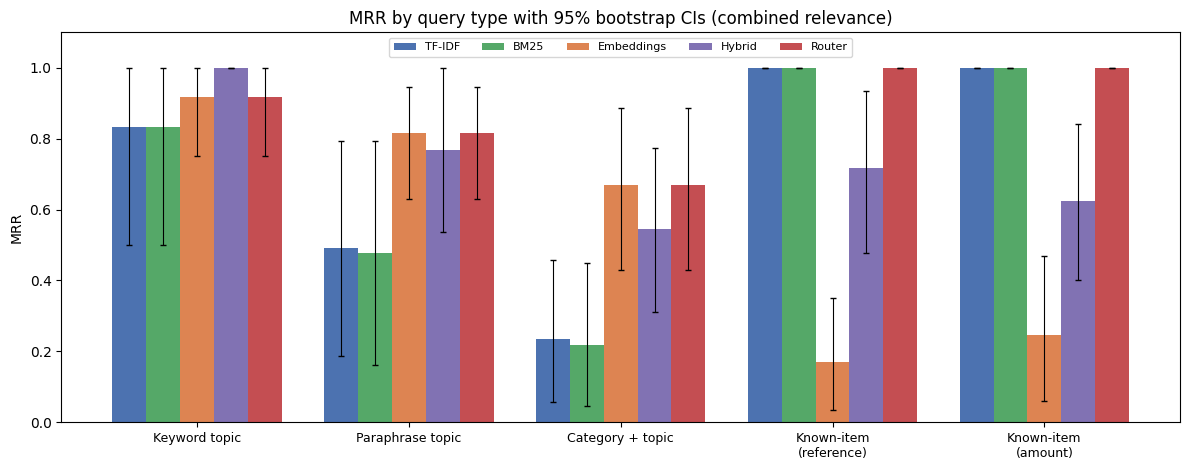

In [50]:
# ===== Step 25: Router + bootstrap confidence intervals + paired comparisons =====
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROUTER = "Router (identifier -> BM25, else Embeddings)"
ID_PATTERN = re.compile(r"REF-\d+|\$\d")

def has_identifier(query):
    return bool(ID_PATTERN.search(query))

def router_ranking(query):
    return retrieve("BM25" if has_identifier(query) else "Embeddings", query)

# --- Evaluate the router exactly like the other methods ---
rt_records = []
for _, q in queries_df.iterrows():
    ranked = router_ranking(q["query"]); top = ranked[:K]
    for definition, rel in [("combined", q["rel_combined"]), ("strict", q["rel_strict"])]:
        hits_top = sum(d in rel for d in top)
        first_rank = next((r for r, d in enumerate(ranked, start=1) if d in rel), None)
        rt_records.append({"qid": q["qid"], "qtype": q["qtype"], "method": ROUTER, "definition": definition,
                           "P@3": hits_top / K, "Hit@3": float(hits_top > 0),
                           "RR": (1.0 / first_rank) if first_rank else 0.0, "n_returned": len(ranked)})
retr = pd.concat([retr[retr["method"] != ROUTER], pd.DataFrame(rt_records)], ignore_index=True)

FIVE = ["TF-IDF", "BM25", "Embeddings", HYBRID, ROUTER]
routed = queries_df["query"].apply(has_identifier)
print("Router sends to BM25:", int(routed.sum()), "queries  |  to Embeddings:", int((~routed).sum()), "queries")
print("Queries routed to BM25 by type:")
display(queries_df.assign(to_bm25=routed).groupby("qtype", sort=False)["to_bm25"].sum().to_frame("routed to BM25"))
print("NOTE: every known-item query contains 'REF-' or '$', so the router equals BM25 on those by construction.\n")

# --- Per-query reciprocal ranks (combined relevance): rows = queries, columns = methods ---
rr = (retr[retr["definition"] == "combined"].pivot_table(index="qid", columns="method", values="RR")[FIVE]
      .join(queries_df.set_index("qid")["qtype"]))

B = 10_000
rng = np.random.default_rng(SEED)

def boot_means(values, idx):
    return values[idx].mean(axis=1)

# --- 1. Bootstrap 95% CI of MRR for each method within each query type ---
ci_rows = []
for qt in QTYPE_ORDER:
    sub = rr[rr["qtype"] == qt]
    n = len(sub)
    idx = rng.integers(0, n, size=(B, n))
    for m in FIVE:
        v = sub[m].to_numpy()
        bm = boot_means(v, idx)
        ci_rows.append({"qtype": qt, "method": m, "n_queries": n, "MRR": v.mean(),
                        "lo": np.percentile(bm, 2.5), "hi": np.percentile(bm, 97.5)})
ci = pd.DataFrame(ci_rows)
ci["MRR [95% CI]"] = ci.apply(lambda r: f"{r['MRR']:.3f} [{r['lo']:.2f}, {r['hi']:.2f}]", axis=1)
print("MRR with 95% bootstrap CI (resampling queries within each type, 10,000 resamples):")
display(ci.pivot(index="qtype", columns="method", values="MRR [95% CI]").reindex(QTYPE_ORDER)[FIVE])

# --- 2. Paired comparisons on the same queries: mean difference in RR, CI, and win/loss counts ---
PAIRS = [("Embeddings", "BM25"), (HYBRID, "Embeddings"), (HYBRID, "BM25"), (ROUTER, HYBRID), (ROUTER, "Embeddings")]
pair_rows = []
for qt in QTYPE_ORDER:
    sub = rr[rr["qtype"] == qt]; n = len(sub)
    idx = rng.integers(0, n, size=(B, n))
    for a, b in PAIRS:
        d = (sub[a] - sub[b]).to_numpy()
        bm = boot_means(d, idx)
        pair_rows.append({"qtype": qt, "A vs B": f"{a.split(' (')[0]} vs {b.split(' (')[0]}",
                          "mean diff (A-B)": d.mean(), "lo": np.percentile(bm, 2.5), "hi": np.percentile(bm, 97.5),
                          "A wins": int((d > 1e-12).sum()), "B wins": int((d < -1e-12).sum()), "ties": int((np.abs(d) <= 1e-12).sum())})
pairs = pd.DataFrame(pair_rows)
pairs["diff [95% CI]"] = pairs.apply(lambda r: f"{r['mean diff (A-B)']:+.3f} [{r['lo']:+.2f}, {r['hi']:+.2f}]", axis=1)
pairs["CI excludes 0?"] = np.where((pairs["lo"] > 0) | (pairs["hi"] < 0), "yes", "no")
print("\nPaired differences in reciprocal rank (A - B) with 95% bootstrap CI, per query type:")
display(pairs[["qtype", "A vs B", "diff [95% CI]", "CI excludes 0?", "A wins", "B wins", "ties"]].reset_index(drop=True))
print("These are descriptive: 5 comparisons x 5 query types = 25 intervals, with no multiple-comparison correction, "
      "and only 6-12 queries per type.")

# --- 3. Chart: MRR with 95% CI error bars ---
fig, ax = plt.subplots(figsize=(12, 4.8))
colors = {"TF-IDF": "#4C72B0", "BM25": "#55A868", "Embeddings": "#DD8452", HYBRID: "#8172B3", ROUTER: "#C44E52"}
x = np.arange(len(QTYPE_ORDER)); w = 0.16
for j, m in enumerate(FIVE):
    s = ci[ci["method"] == m].set_index("qtype").reindex(QTYPE_ORDER)
    ax.bar(x + (j - 2) * w, s["MRR"], w, label=m.split(" (")[0], color=colors[m],
           yerr=[s["MRR"] - s["lo"], s["hi"] - s["MRR"]], capsize=2, error_kw={"lw": 0.8})
ax.set_xticks(x); ax.set_xticklabels([q.replace(" (", "\n(") for q in QTYPE_ORDER], fontsize=9)
ax.set_ylim(0, 1.1); ax.set_ylabel("MRR"); ax.set_title("MRR by query type with 95% bootstrap CIs (combined relevance)")
ax.legend(fontsize=8, ncol=5, loc="upper center"); plt.tight_layout(); plt.show()

### Results and Interpretation

**Router.** Of the 51 queries, 24 contained an identifier (`REF-` or `$`) and were routed to BM25; the other 27 went to embeddings. On the 24 known-item queries the router equals BM25 by construction, and on the other 27 it equals the embedding retriever, so its results are the best single method per query type and not an independent discovery. Its score is also somewhat optimistic, because choosing embeddings for non-identifier queries was informed by the same 51 queries.

**Confidence intervals.** With only 6–12 queries per type, the intervals are wide. For example, MRR on category + topic queries was 0.670 for embeddings (95% CI 0.43–0.89), 0.544 for the hybrid (0.31–0.77) and 0.217 for BM25 (0.04–0.45). Intervals of exactly [1.00, 1.00] for BM25, TF-IDF and the router on known-item queries arise because all 12 queries scored 1.0, so resampling produces no variation. This is not proof of perfection: by the rule of three, 0 failures in 12 queries is consistent with a true failure rate of up to about 25%.

**Paired comparisons** (difference in reciprocal rank on the same queries):

- *Known-item queries (reference and amount):* BM25 was clearly better than embeddings (differences of −0.831 and −0.754 for embeddings vs BM25, CIs excluding zero) and also better than the hybrid (−0.283 and −0.375, CIs excluding zero). The hybrid was clearly better than embeddings alone (+0.548 and +0.379). The ordering BM25 > hybrid > embeddings holds in both known-item types.
- *Category + topic queries:* embeddings beat BM25 (+0.453, CI 0.06 to 0.79, 10 query wins to 2) and the hybrid beat BM25 (+0.328, CI 0.05 to 0.61). The hybrid versus embeddings difference (−0.126, CI −0.40 to +0.14) cannot be distinguished from zero.
- *Paraphrase queries:* embeddings were ahead of BM25 by +0.338 (5 query wins, 2 losses), but the interval (−0.08 to +0.73) includes zero. The hybrid beat BM25 (+0.292, CI 0.07 to 0.55). Hybrid versus embeddings was not distinguishable (−0.046, CI −0.31 to +0.22).
- *Keyword queries:* no pairwise difference could be distinguished from zero, which is expected with 6 queries.

**Limitations.** The 25 intervals are unadjusted for multiple comparisons and should be read as descriptive. Queries within a type are related (for instance, several paraphrases of one topic), so the bootstrap probably understates the true uncertainty. All labels and queries come from the same synthetic generator, so absolute scores are more favorable than real documents would give.

**Key Takeaway:** The one clearly supported finding is that exact-identifier queries need lexical search (BM25 beats both the hybrid and embeddings with intervals excluding zero), while meaning-based queries are better served by embeddings than by BM25 on category queries. For the remaining comparisons, in particular embeddings versus the hybrid on non-identifier queries, the data cannot separate the methods. Since the hybrid adds complexity without a demonstrated gain over embeddings on those queries, the simplest well-supported design is a router: identifier-like queries to BM25, all others to embeddings. This design should be confirmed on real documents before deployment.